#### Script Comments
##### File associated with 'FullfilementPlanAU'
Author: Ruben A. Proano (rpmeie@rit.edu)

This code should be used using the output stored in file **aa** (or **aa2**), which is output of the simulation study from code "FullfilementPlanAU". Scripts in this file generate the data, tables, and figures used in the associated paper

This code is licensed under a **Creative Commons Attribution 4.0 International License** https://creativecommons.org/licenses/by/4.0/

Attribution the data and code should include:

    Ruben A. Proano, Rochester Institute of Technology, rpmeie@rit.edu
    Copyright notice (© 2025 R.Proano)
    Add a link to the original work (paper link)
--- 

**aa** : object that collects simulation output for study using data set 1
**aa2** : object that collects simulation output for study using data set 2 

#### Column headings of **aa** (or **aa2**)
- vac: vaccine
- g_rep: tuple for (g-value, replication)
- v2/v1: ratio between the profit-per-dose of a vaccine made and sold in AU Gavi countries and the profit-per-dose of the same vaccine if made and sold in non-AU Gavi countries. 
- v3/v1: ratio between the profit-per-dose of a vaccine made in non-AU Gavi countries and sold in AU Gavi countries and the the profit-per-dose of the same vaccine if made and sold in non-AU Gavi countries. 
- K1: non-AU vaccine production capacity
- K2: AU vaccine production capacity
- scenario: Profit scenario based on the relationship of the profit per dose for procurement scenarios (v1, v2, v3)
- area: profit scenario area based on the simulated vaccine profits and capacities
- xD: optimal profit-driven fulfillement for vaccines made and sold in non-AU countries (procurement interaction NN)
- xO: optimal profit-driven fulfillement for vaccines made and sold in AU countries (procurement interaction AA)
- xT: optimal profit-driven fulfillement for vaccines made in non-AU countries and sold in AU (procurement interaction NA)
- pfD:profit for procurement interaction NN (when there is AU production)
- pfO: profit for procurement interaction AA (when there is AU producton)
- pfT: profit for procurement interaction NA (when there is AU production)
- bpfD: benchmark profit for procurement interaction NN (when there is no AU production)
- bpfO: benchmark profit for procurement interaction AA (when there is no AU production)
- bpfT: benchmark profit for procurement interaction NA (when there is no AU production)
- pDtot: pfD + pfT
- bpfDtot: bpfD + bpfT
- g: proportion of the African vaccine demand that aims to be supplied with domestic production
- rep: replication

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as sc
import matplotlib.pyplot as plt  
import seaborn as sns
import zipfile

df = pd.read_csv('aa2.zip',compression='zip')

### Displaying column headers of file **aa**, simulation output

In [2]:
df.columns


Index(['vac', 'g_rep', 'v2/v1', 'v3/v1', 'K1', 'K2', 'scenario', 'area', 'xD',
       'xO', 'xT', 'pfD', 'pfO', 'pfT', 'bpfD', 'bpfO', 'bpfT', 'pDtot',
       'bpfDtot', 'g', 'rep'],
      dtype='object')

In [3]:
df.head()

,vac,g_rep,v2/v1,v3/v1,K1,K2,scenario,area,xD,xO,...,pfD,pfO,pfT,bpfD,bpfO,bpfT,pDtot,bpfDtot,g,rep
0,HPV,"(0.0, 0)",0.973027,1.006492,18000000.0,0.0,5,a_3,0.000000e+00,0.0,...,0.000000e+00,0.0,8.516205e+07,0.000000e+00,0.0,8.516205e+07,8.516205e+07,8.516205e+07,0.0,0.0
1,HPV,"(0.0, 1)",0.987083,0.985497,18000000.0,0.0,1,a_2,7.024872e+06,0.0,...,3.213221e+07,0.0,4.947285e+07,3.213221e+07,0.0,4.947285e+07,8.160507e+07,8.160507e+07,0.0,1.0
2,HPV,"(0.0, 2)",0.995180,1.024999,18000000.0,0.0,5,a_2,4.418239e+05,0.0,...,2.060216e+06,0.0,8.392018e+07,2.060216e+06,0.0,8.392018e+07,8.598040e+07,8.598040e+07,0.0,2.0
3,HPV,"(0.0, 3)",1.046258,1.015089,18000000.0,0.0,4,a_2,2.789016e+06,0.0,...,1.246823e+07,0.0,6.902644e+07,1.246823e+07,0.0,6.902644e+07,8.149467e+07,8.149467e+07,0.0,3.0
4,HPV,"(0.0, 4)",0.991900,0.996475,18000000.0,0.0,2,a_2,5.340945e+06,0.0,...,2.429092e+07,0.0,5.737116e+07,2.429092e+07,0.0,5.737116e+07,8.166208e+07,8.166208e+07,0.0,4.0


In [4]:
df.groupby(['vac','g','scenario']).mean(numeric_only=True)

v2/v1     v3/v1          K1          K2            xD  \
vac g   scenario                                                             
HPV 0.0 1         0.980596  0.962506  18000000.0         0.0  5.632348e+06   
        2         0.961224  0.979169  18000000.0         0.0  5.610848e+06   
        3         1.020791  0.981728  18000000.0         0.0  5.603498e+06   
        4         1.040435  1.019060  18000000.0         0.0  1.325958e+06   
        5         1.000540  1.030990  18000000.0         0.0  1.309982e+06   
...                    ...       ...         ...         ...           ...   
YF  1.0 1         0.971790  0.942510    380000.0  37620000.0  3.547777e+05   
        2         0.941537  0.970664    380000.0  37620000.0  3.552766e+05   
        3         1.029799  0.970319    380000.0  37620000.0  3.544628e+05   
        4         1.063159  1.032280    380000.0  37620000.0  1.134218e+05   
        5         1.001151  1.046831    380000.0  37620000.0  1.109952e+05   

                            xO            xT           pfD           pfO  \
vac g   scenario                                                           
HPV 0.0 1         0.000000e+00  1.222353e+07  2.662397e+07  0.000000e+00   
        2         0.000000e+00  1.227095e+07  2.655989e+07  0.000000e+00   
        3         0.000000e+00  1.226539e+07  2.597623e+07  0.000000e+00   
        4         0.000000e+00  1.655372e+07  6.030708e+06  0.000000e+00   
        5         0.000000e+00  1.656397e+07  6.014152e+06  0.000000e+00   
...                        ...           ...           ...           ...   
YF  1.0 1         3.504391e+07  1.709650e+04  4.664000e+05  4.476941e+07   
        2         3.511642e+07  2.472340e+04  4.674221e+05  4.349185e+07   
        3         3.498390e+07  1.640505e+04  4.528213e+05  4.600492e+07   
        4         3.525477e+07  2.589651e+05  1.404909e+05  4.638947e+07   
        5         3.510605e+07  2.690048e+05  1.393608e+05  4.415630e+07   

                           pfT          bpfD  bpfO          bpfT  \
vac g   scenario                                                   
HPV 0.0 1         5.561847e+07  2.662397e+07   0.0  5.561847e+07   
        2         5.685661e+07  2.655989e+07   0.0  5.685661e+07   
        3         5.581108e+07  2.597623e+07   0.0  5.581108e+07   
        4         7.674261e+07  6.030708e+06   0.0  7.674261e+07   
        5         7.837895e+07  6.014152e+06   0.0  7.837895e+07   
...                        ...           ...   ...           ...   
YF  1.0 1         2.115385e+04  6.293481e+05   0.0  4.332955e+07   
        2         3.160644e+04  6.359939e+05   0.0  4.476016e+07   
        3         2.027122e+04  6.146816e+05   0.0  4.325474e+07   
        4         3.310168e+05  1.900539e+05   0.0  4.538269e+07   
        5         3.538132e+05  1.854658e+05   0.0  4.653203e+07   

                         pDtot       bpfDtot          rep  
vac g   scenario                                           
HPV 0.0 1         8.224243e+07  8.224243e+07  5050.283988  
        2         8.341650e+07  8.341650e+07  4886.372807  
        3         8.178732e+07  8.178732e+07  4901.989241  
        4         8.277332e+07  8.277332e+07  4961.344489  
        5         8.439310e+07  8.439310e+07  5096.946156  
...                        ...           ...          ...  
YF  1.0 1         4.875539e+05  4.395890e+07  5056.235435  
        2         4.990285e+05  4.539616e+07  4944.658288  
        3         4.730925e+05  4.386942e+07  5073.817044  
        4         4.715076e+05  4.557274e+07  4966.408408  
        5         4.931740e+05  4.671750e+07  4977.690154  

[240 rows x 16 columns]

#### Modifying dataframe that reads content of **aa** by adding content net benefit, benefit, market value, and benfit-ratio columns. Then create a second data frame that groups (averages) the content by vaccine, g-level, and profit scenario

In [5]:
df['pDdif']=df['pfD']-df['bpfD']
df['pOdif']=df['pfO']-df['bpfO']
df['pTdif']=df['pfT']-df['bpfT']
df['benefit']=df['pDdif']+df['pOdif']+df['pTdif']
df['marketvalue_o']=df['bpfD']+df['bpfO']+df['bpfT']
df['marketvalue_n']=df['pfD']+df['pfO']+df['pfT']
df['ben_mv']=df['benefit']/df['marketvalue_o']
df2=df.groupby(['vac','g','scenario'], as_index=False).agg({'pDdif':['mean','std','count'],'pOdif':['mean','std','count'],'pTdif':['mean','std','count'],'benefit':['mean','std','count'], 'ben_mv':['mean','std','count'],'marketvalue_o':['mean','std','count']})


In [6]:
df2.columns

MultiIndex([(          'vac',      ''),
            (            'g',      ''),
            (     'scenario',      ''),
            (        'pDdif',  'mean'),
            (        'pDdif',   'std'),
            (        'pDdif', 'count'),
            (        'pOdif',  'mean'),
            (        'pOdif',   'std'),
            (        'pOdif', 'count'),
            (        'pTdif',  'mean'),
            (        'pTdif',   'std'),
            (        'pTdif', 'count'),
            (      'benefit',  'mean'),
            (      'benefit',   'std'),
            (      'benefit', 'count'),
            (       'ben_mv',  'mean'),
            (       'ben_mv',   'std'),
            (       'ben_mv', 'count'),
            ('marketvalue_o',  'mean'),
            ('marketvalue_o',   'std'),
            ('marketvalue_o', 'count')],
           )

In [7]:
df2.columns = [
'_'.join(col).rstrip('_') for col in df2.columns.values
]

#### Computing noise-mean ratio values for the average profit changes

In [8]:
 CV = lambda a, b: a.div(b)


In [9]:
df2['pDdif_CV']=CV(df2['pDdif_std'], df2['pDdif_mean'])
df2['pOdif_CV']=CV(df2['pOdif_std'], df2['pOdif_mean'])
df2['pTdif_CV']=CV(df2['pTdif_std'], df2['pTdif_mean'])

In [10]:
df2

,vac,g,scenario,pDdif_mean,pDdif_std,pDdif_count,pOdif_mean,pOdif_std,pOdif_count,pTdif_mean,...,benefit_count,ben_mv_mean,ben_mv_std,ben_mv_count,marketvalue_o_mean,marketvalue_o_std,marketvalue_o_count,pDdif_CV,pOdif_CV,pTdif_CV
0,HPV,0.0,1,0.000000,0.000000,1655,0.000000e+00,0.000000e+00,1655,0.000000e+00,...,1655,0.000000,0.000000,1655,8.224243e+07,2.759797e+06,1655,NaN,NaN,NaN
1,HPV,0.0,2,0.000000,0.000000,1596,0.000000e+00,0.000000e+00,1596,0.000000e+00,...,1596,0.000000,0.000000,1596,8.341650e+07,2.635864e+06,1596,NaN,NaN,NaN
2,HPV,0.0,3,0.000000,0.000000,1673,0.000000e+00,0.000000e+00,1673,0.000000e+00,...,1673,0.000000,0.000000,1673,8.178732e+07,2.556114e+06,1673,NaN,NaN,NaN
3,HPV,0.0,4,0.000000,0.000000,1733,0.000000e+00,0.000000e+00,1733,0.000000e+00,...,1733,0.000000,0.000000,1733,8.277332e+07,2.760054e+06,1733,NaN,NaN,NaN
4,HPV,0.0,5,0.000000,0.000000,3343,0.000000e+00,0.000000e+00,3343,0.000000e+00,...,3343,0.000000,0.000000,3343,8.439310e+07,2.830143e+06,3343,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,YF,1.0,1,-162948.105183,158115.909443,1665,4.476941e+07,6.099341e+06,1665,-4.330840e+07,...,1665,0.029597,0.024631,1665,4.395890e+07,5.880631e+06,1665,-0.970345,0.136239,-0.135287
236,YF,1.0,2,-168571.842809,160924.893514,1671,4.349185e+07,5.754319e+06,1671,-4.472856e+07,...,1671,-0.030922,0.022924,1671,4.539616e+07,5.868351e+06,1671,-0.954637,0.132308,-0.131132
237,YF,1.0,3,-161860.312797,154892.437307,1678,4.600492e+07,6.347063e+06,1678,-4.323447e+07,...,1678,0.059573,0.029607,1678,4.386942e+07,5.936186e+06,1678,-0.956951,0.137965,-0.136812
238,YF,1.0,4,-49563.094106,110617.453497,1665,4.638947e+07,5.770511e+06,1665,-4.505167e+07,...,1665,0.028397,0.022955,1665,4.557274e+07,5.604179e+06,1665,-2.231851,0.124393,-0.125293


In [11]:
df2['pDdif_se']=df2['pDdif_std']/df2['pDdif_count']
df2['pOdif_se']=df2['pOdif_std']/df2['pOdif_count']
df2['pTdif_se']=df2['pTdif_std']/df2['pTdif_count']

<Axes: xlabel='scenario'>

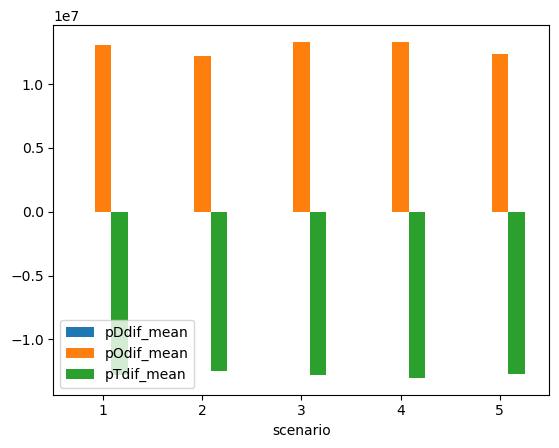

In [12]:
df2[(df2['vac']=='HPV')&(df2['g']==0.2)].plot(x='scenario',y=['pDdif_mean','pOdif_mean','pTdif_mean'], kind='bar', rot=0)

In [13]:
vaclist=list(df['vac'].unique())
glist=list(df['g'].unique().round(1).tolist())
scenariolist=list(df['scenario'].unique())
scenariolist.sort()

In [14]:
vaclist

['HPV', 'IPV', 'MR', 'OCV', 'PCV', 'Penta', 'Rota', 'YF']

In [15]:
pd.set_option('display.precision', 3)
df2[['vac','g','scenario','pDdif_mean','pOdif_mean','pTdif_mean']]

,vac,g,scenario,pDdif_mean,pOdif_mean,pTdif_mean
0,HPV,0.0,1,0.000,0.000e+00,0.000e+00
1,HPV,0.0,2,0.000,0.000e+00,0.000e+00
2,HPV,0.0,3,0.000,0.000e+00,0.000e+00
3,HPV,0.0,4,0.000,0.000e+00,0.000e+00
4,HPV,0.0,5,0.000,0.000e+00,0.000e+00
...,...,...,...,...,...,...
235,YF,1.0,1,-162948.105,4.477e+07,-4.331e+07
236,YF,1.0,2,-168571.843,4.349e+07,-4.473e+07
237,YF,1.0,3,-161860.313,4.600e+07,-4.323e+07
238,YF,1.0,4,-49563.094,4.639e+07,-4.505e+07


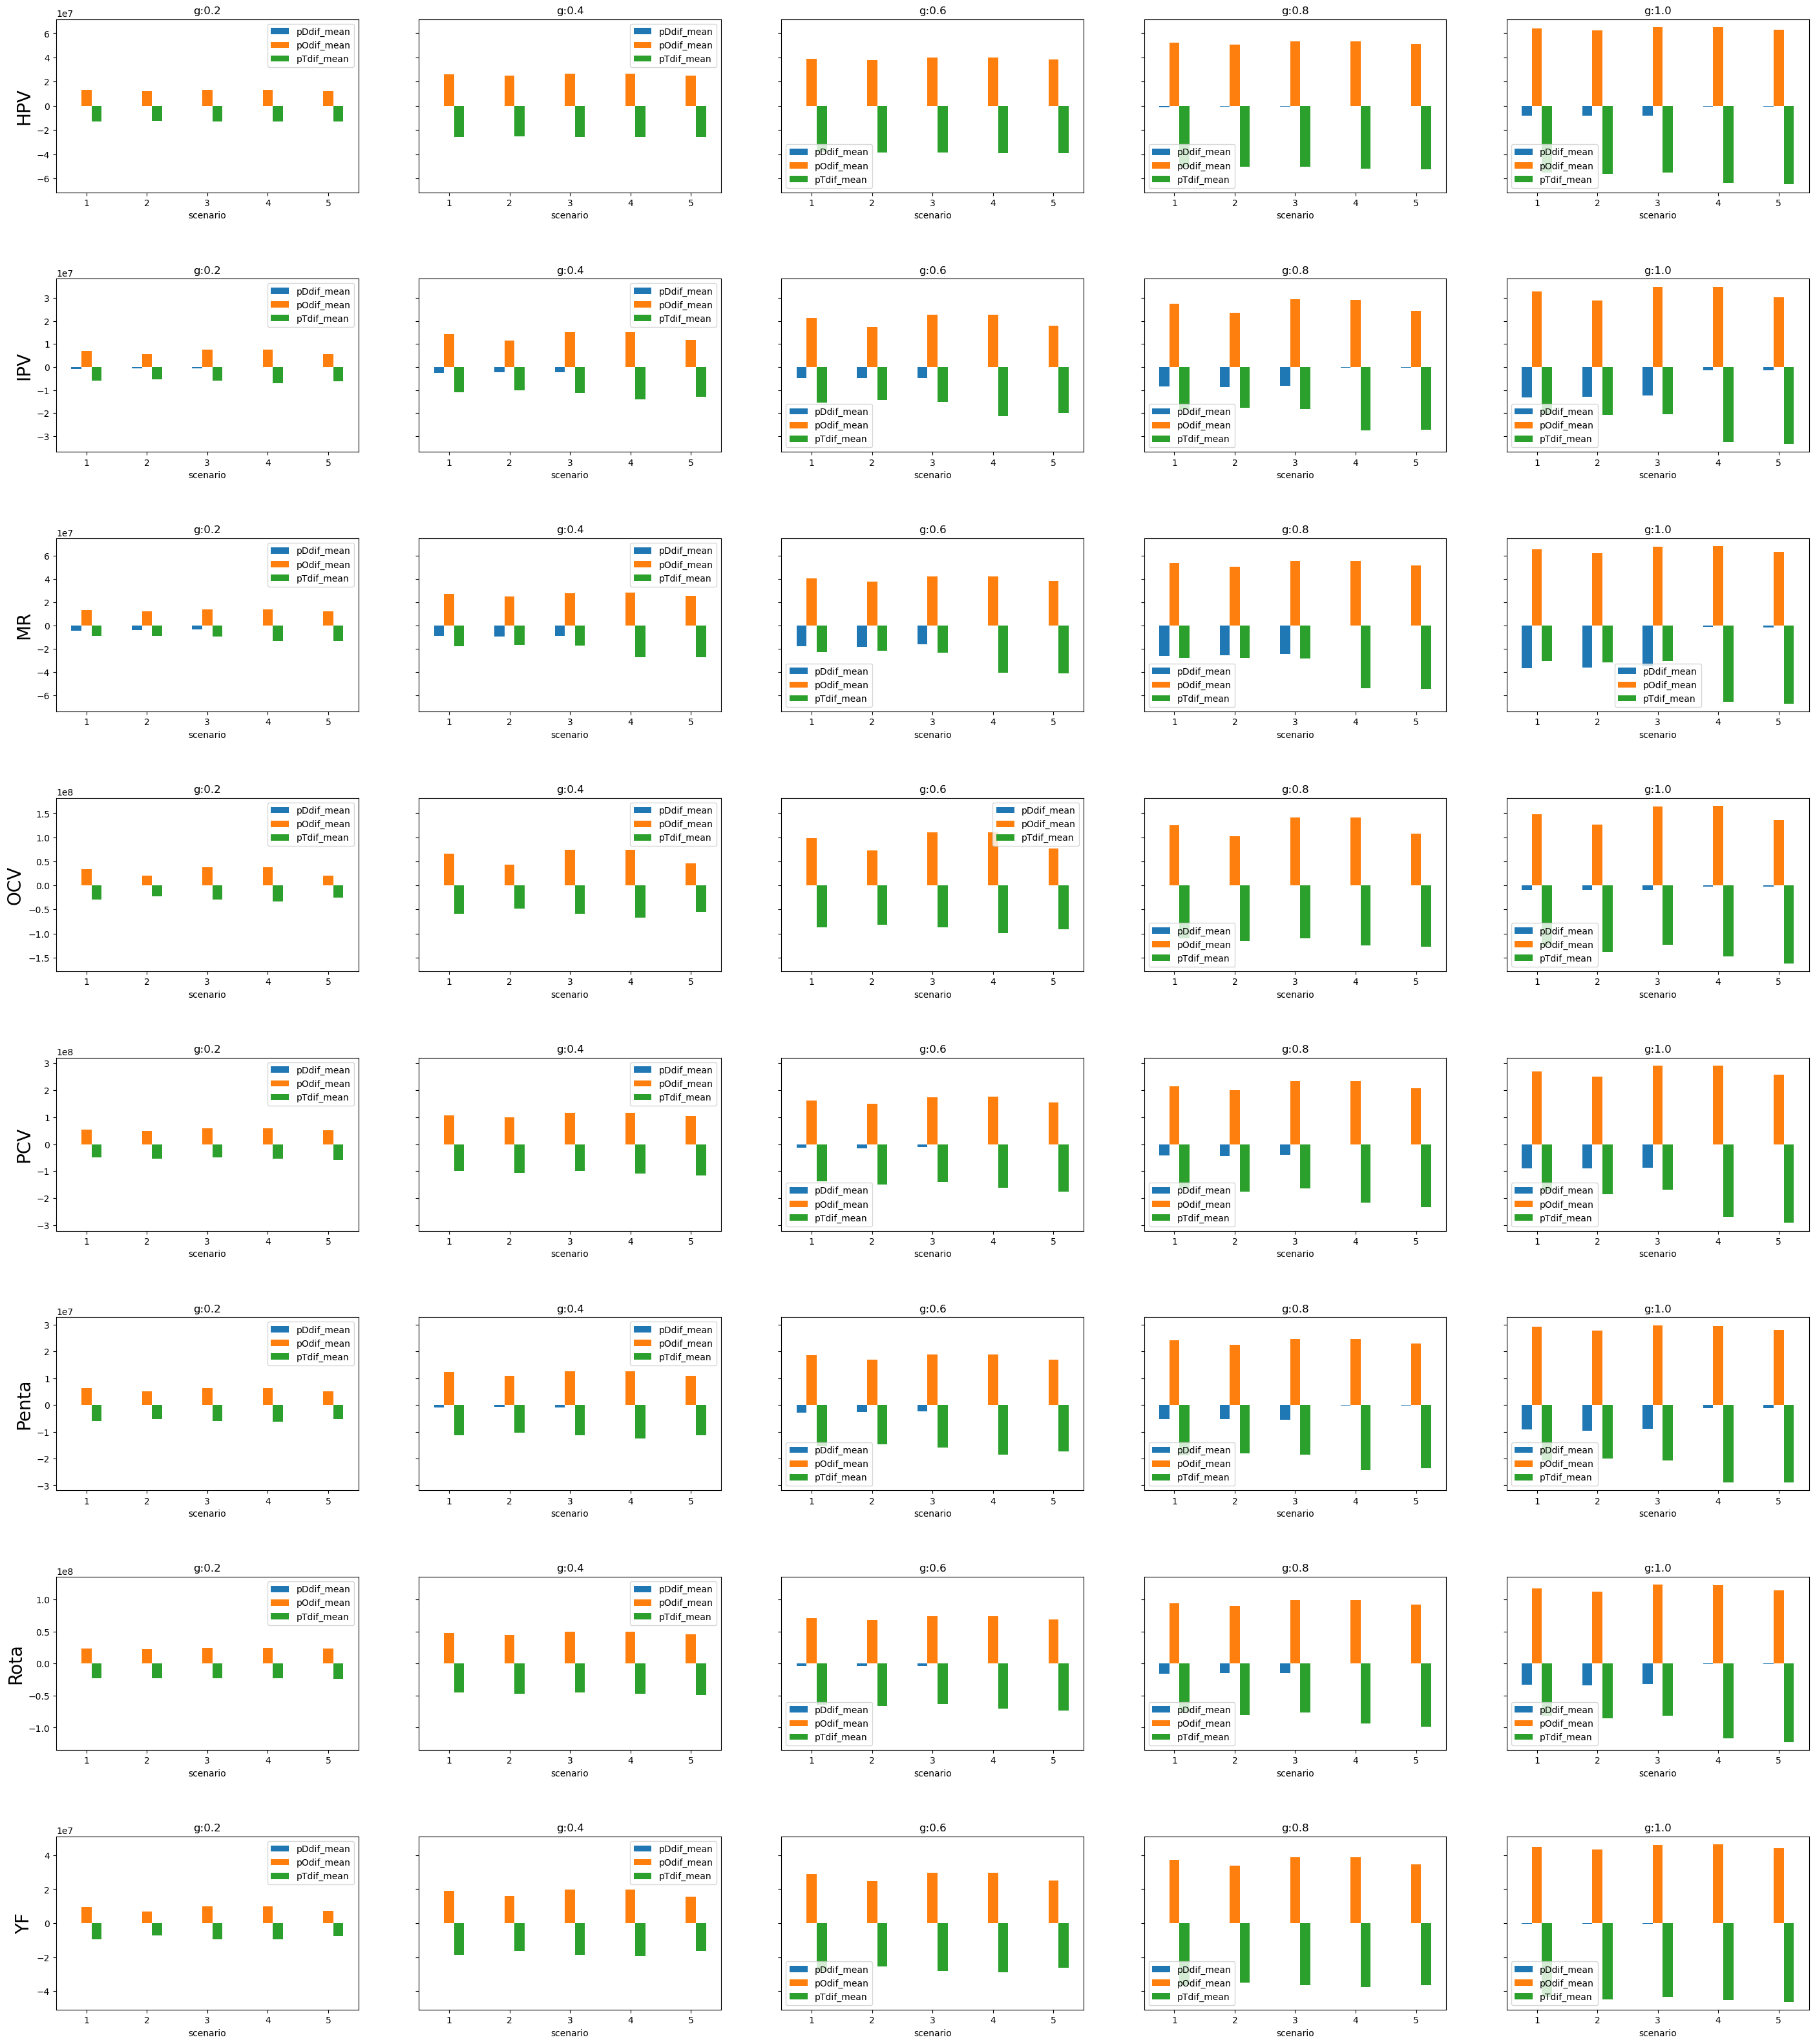

In [16]:
#import pandas as pd
#import matplotlib.pyplot as plt

fig, axes = plt.subplots( nrows=len(vaclist), ncols=len(glist)-1, sharey='row',figsize=(35, 40))

for vc in vaclist:
    for g in glist[1:]:
        df2[(df2['vac']==vc)&(df2['g']==g)].plot(x='scenario',y=['pDdif_mean','pOdif_mean','pTdif_mean'], kind='bar', rot=0, ax=axes[vaclist.index(vc)][glist.index(g)-1])
        axes[vaclist.index(vc)][glist.index(g)-1].set_title(f"g:{g}")
        fig.subplots_adjust(hspace=.5)
    axes[vaclist.index(vc),0].set_ylabel(f'{vc}', rotation=90, size=20)
plt.show()


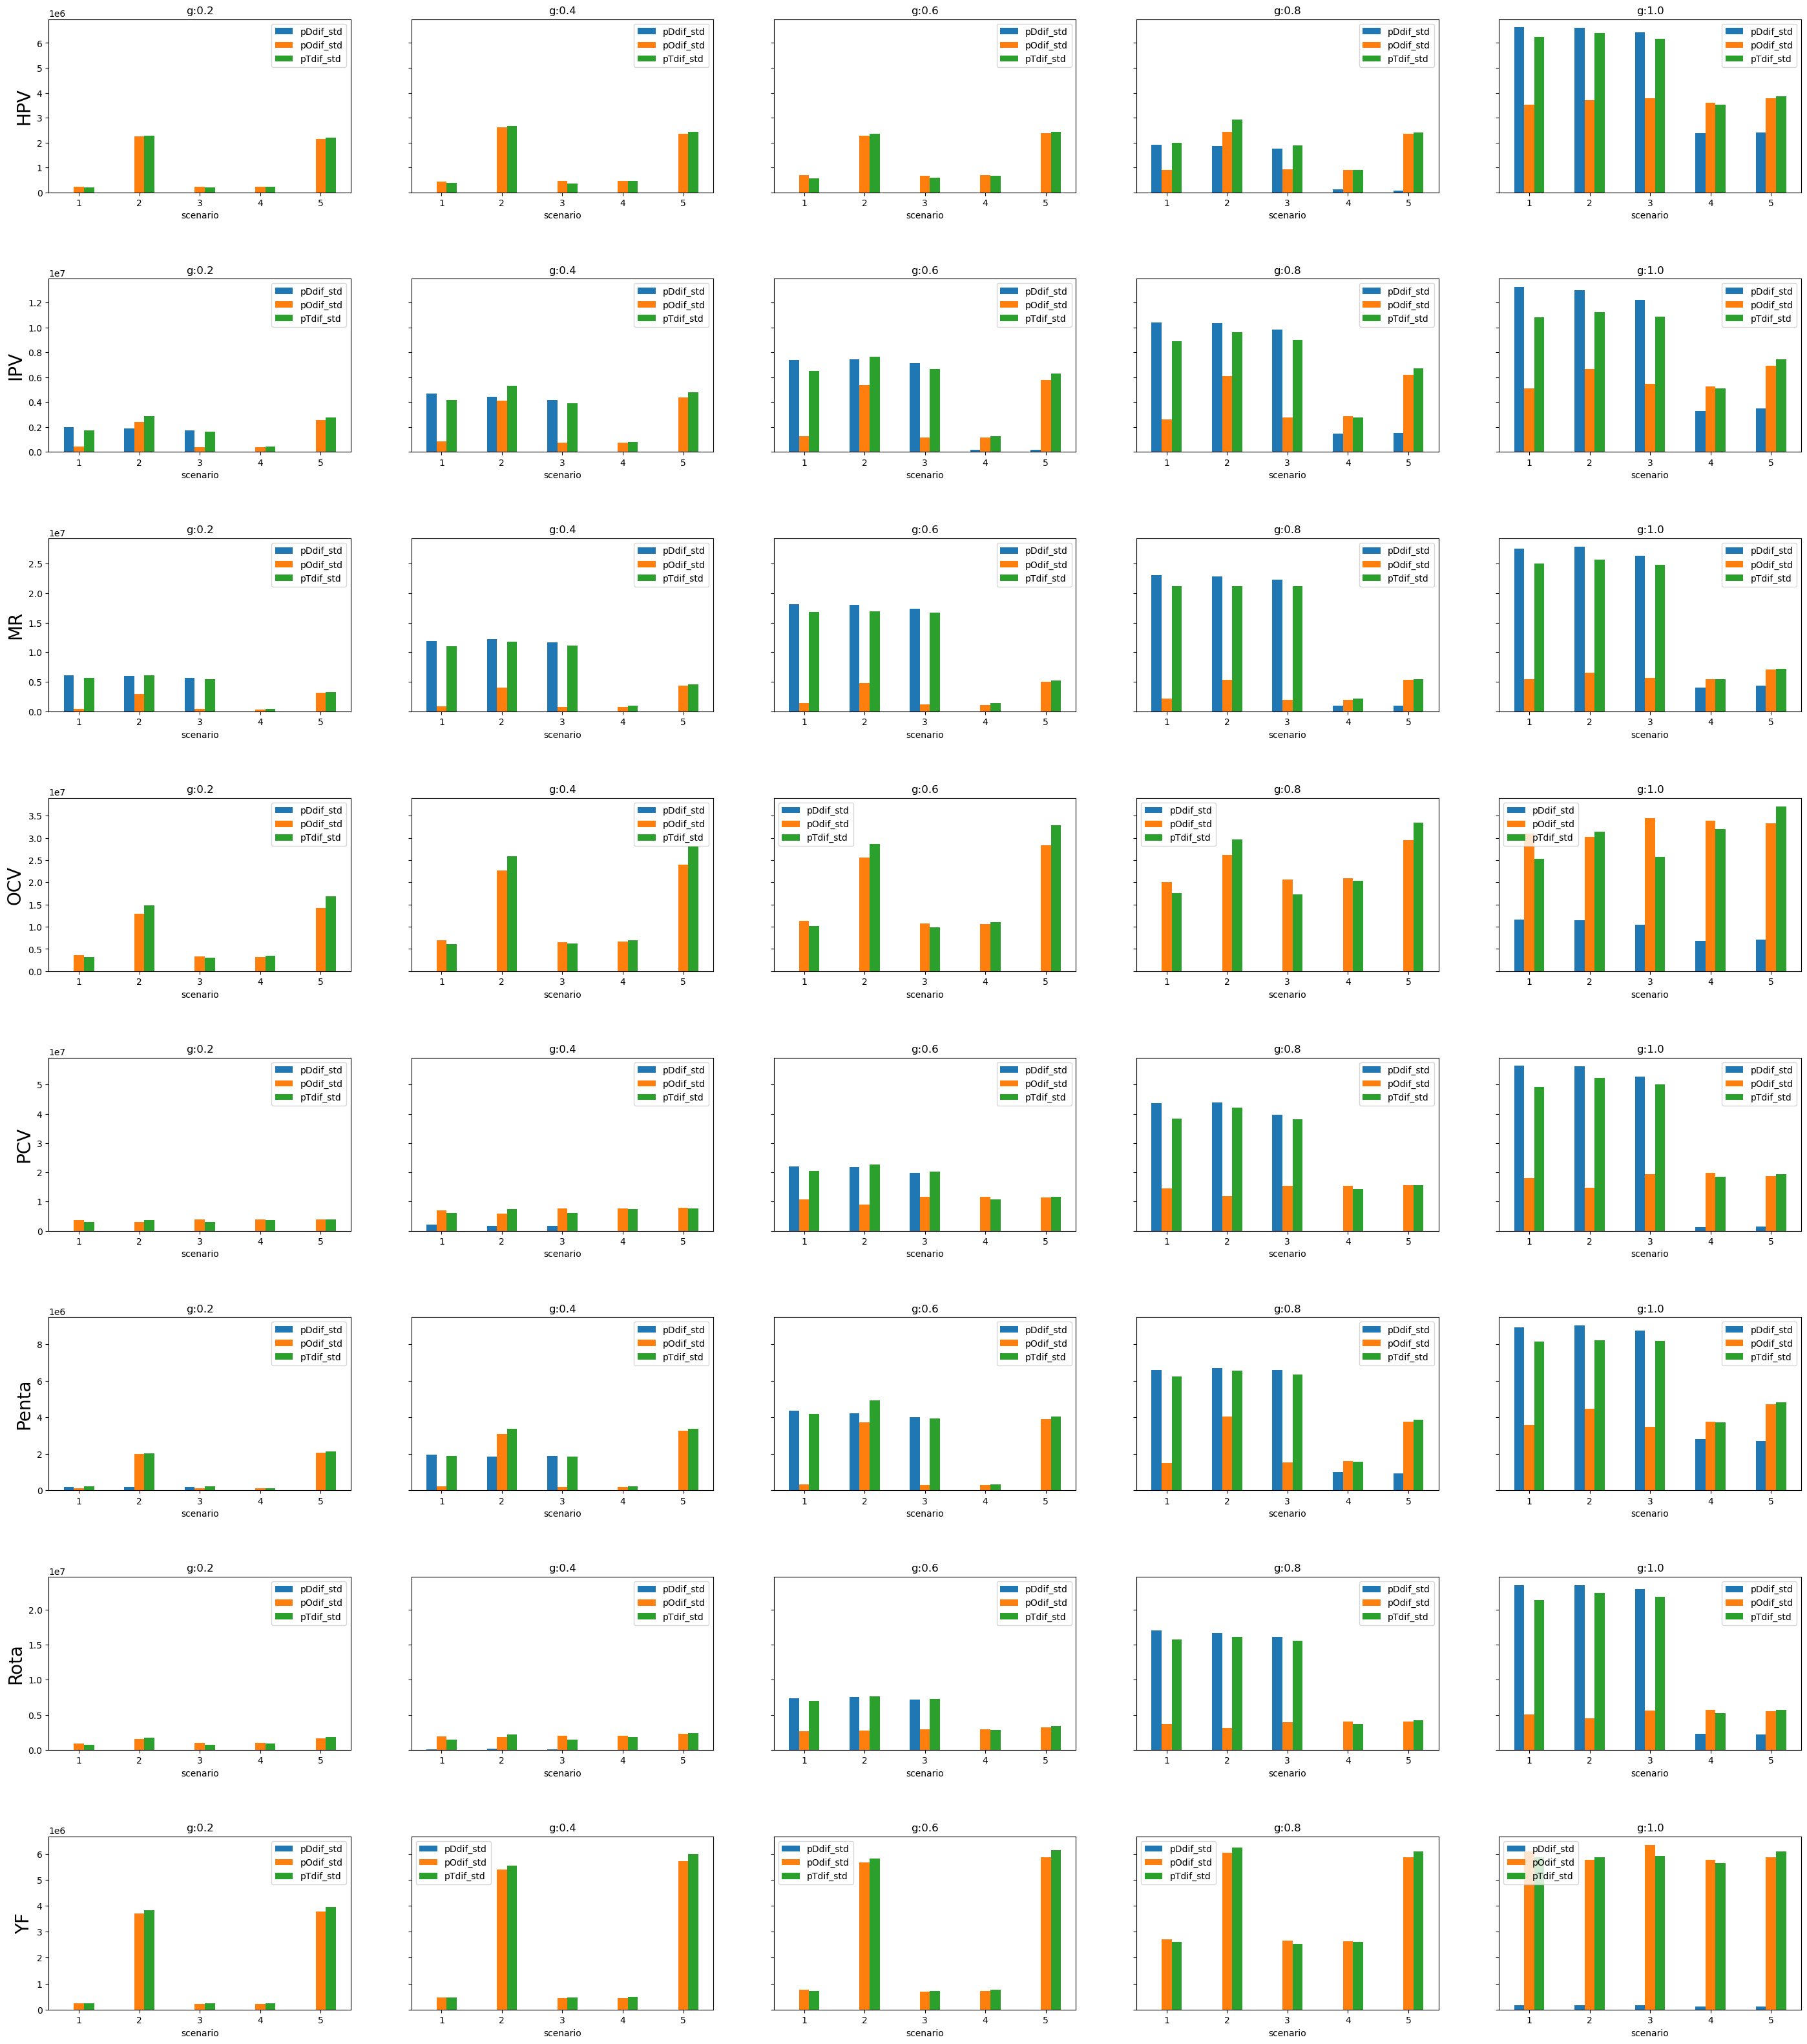

In [17]:
fig, axes = plt.subplots( nrows=len(vaclist), ncols=len(glist)-1, sharey='row',figsize=(35, 40) )

for vc in vaclist:
    for g in glist[1:]:
        df2[(df2['vac']==vc)&(df2['g']==g)].plot(x='scenario',y=['pDdif_std','pOdif_std','pTdif_std'], kind='bar', rot=0, ax=axes[vaclist.index(vc)][glist.index(g)-1])
        axes[vaclist.index(vc)][glist.index(g)-1].set_title(f"g:{g}")
        fig.subplots_adjust(hspace=.5)
    axes[vaclist.index(vc),0].set_ylabel(f'{vc}', rotation=90, size=20)
plt.show()

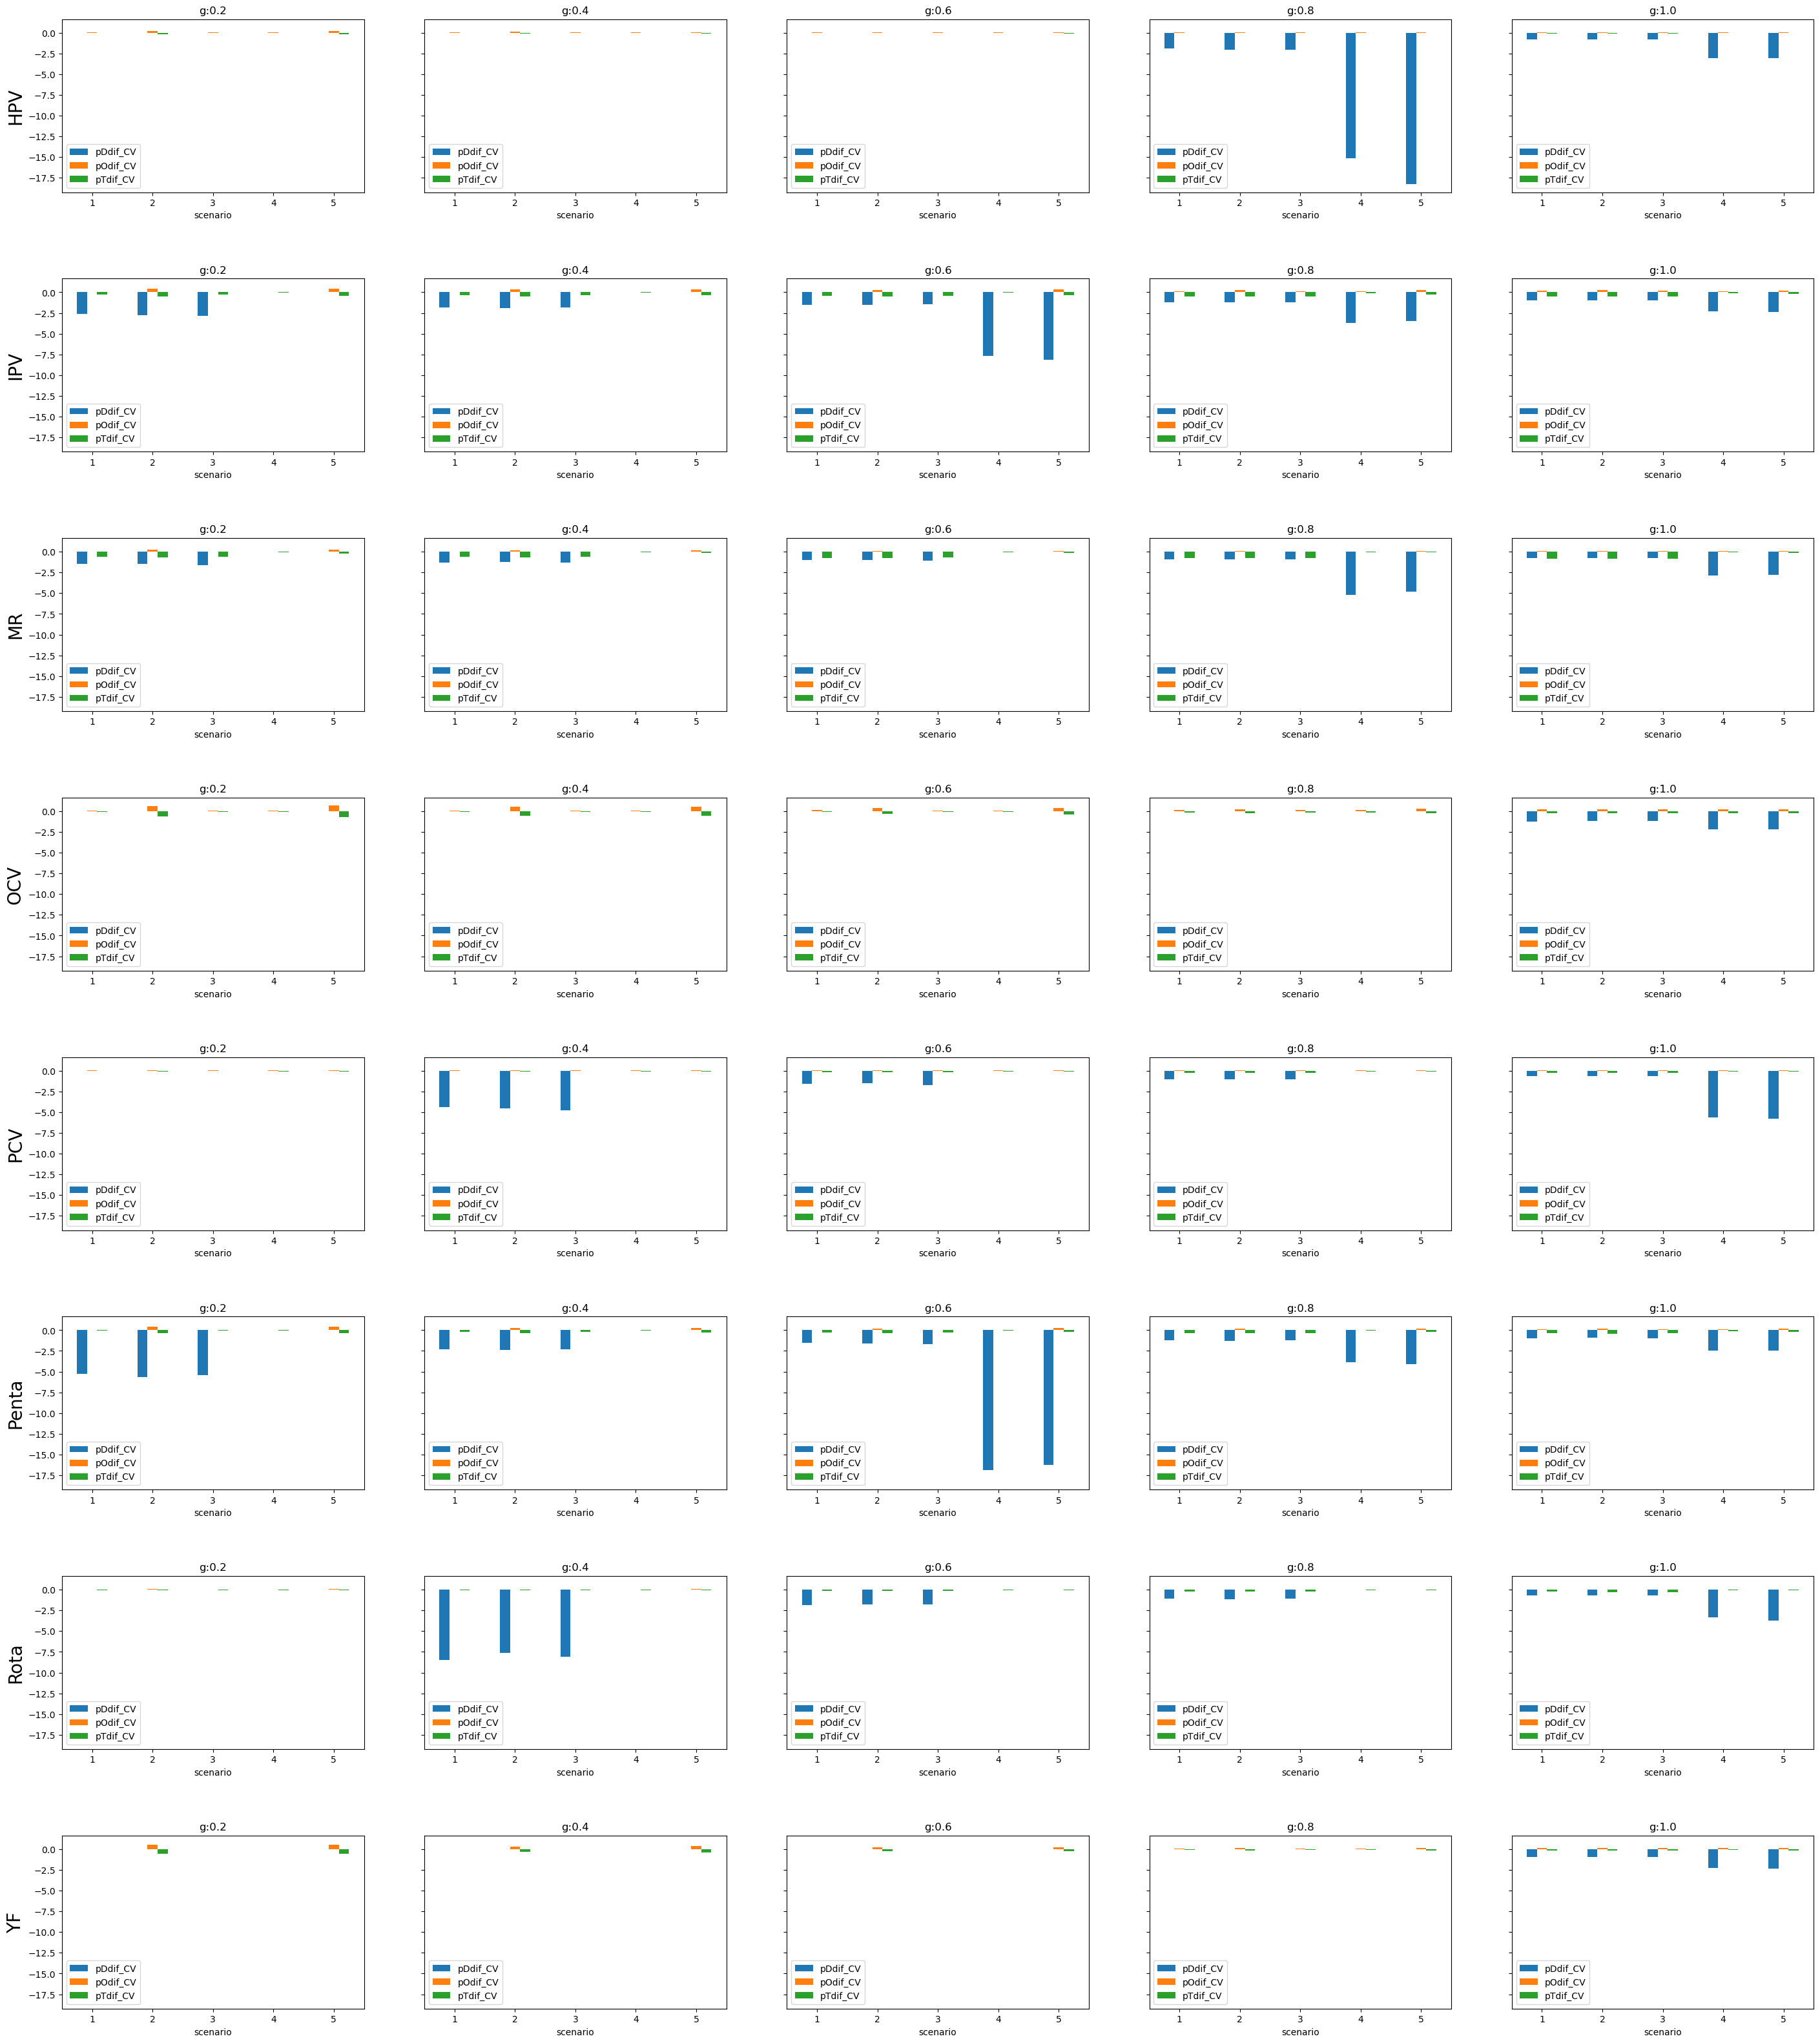

In [18]:
fig, axes = plt.subplots( nrows=len(vaclist), ncols=len(glist)-1, sharey='all',figsize=(35, 40) )

for vc in vaclist:
    for g in glist[1:]:
        df2[(df2['vac']==vc)&(df2['g']==g)].plot(x='scenario',y=['pDdif_CV','pOdif_CV','pTdif_CV'], kind='bar', rot=0, ax=axes[vaclist.index(vc)][glist.index(g)-1])
        axes[vaclist.index(vc)][glist.index(g)-1].set_title(f"g:{g}")
        fig.subplots_adjust(hspace=.5)
    axes[vaclist.index(vc),0].set_ylabel(f'{vc}', rotation=90, size=20)
plt.show()

In [19]:
df2.columns

Index(['vac', 'g', 'scenario', 'pDdif_mean', 'pDdif_std', 'pDdif_count',
       'pOdif_mean', 'pOdif_std', 'pOdif_count', 'pTdif_mean', 'pTdif_std',
       'pTdif_count', 'benefit_mean', 'benefit_std', 'benefit_count',
       'ben_mv_mean', 'ben_mv_std', 'ben_mv_count', 'marketvalue_o_mean',
       'marketvalue_o_std', 'marketvalue_o_count', 'pDdif_CV', 'pOdif_CV',
       'pTdif_CV', 'pDdif_se', 'pOdif_se', 'pTdif_se'],
      dtype='object')

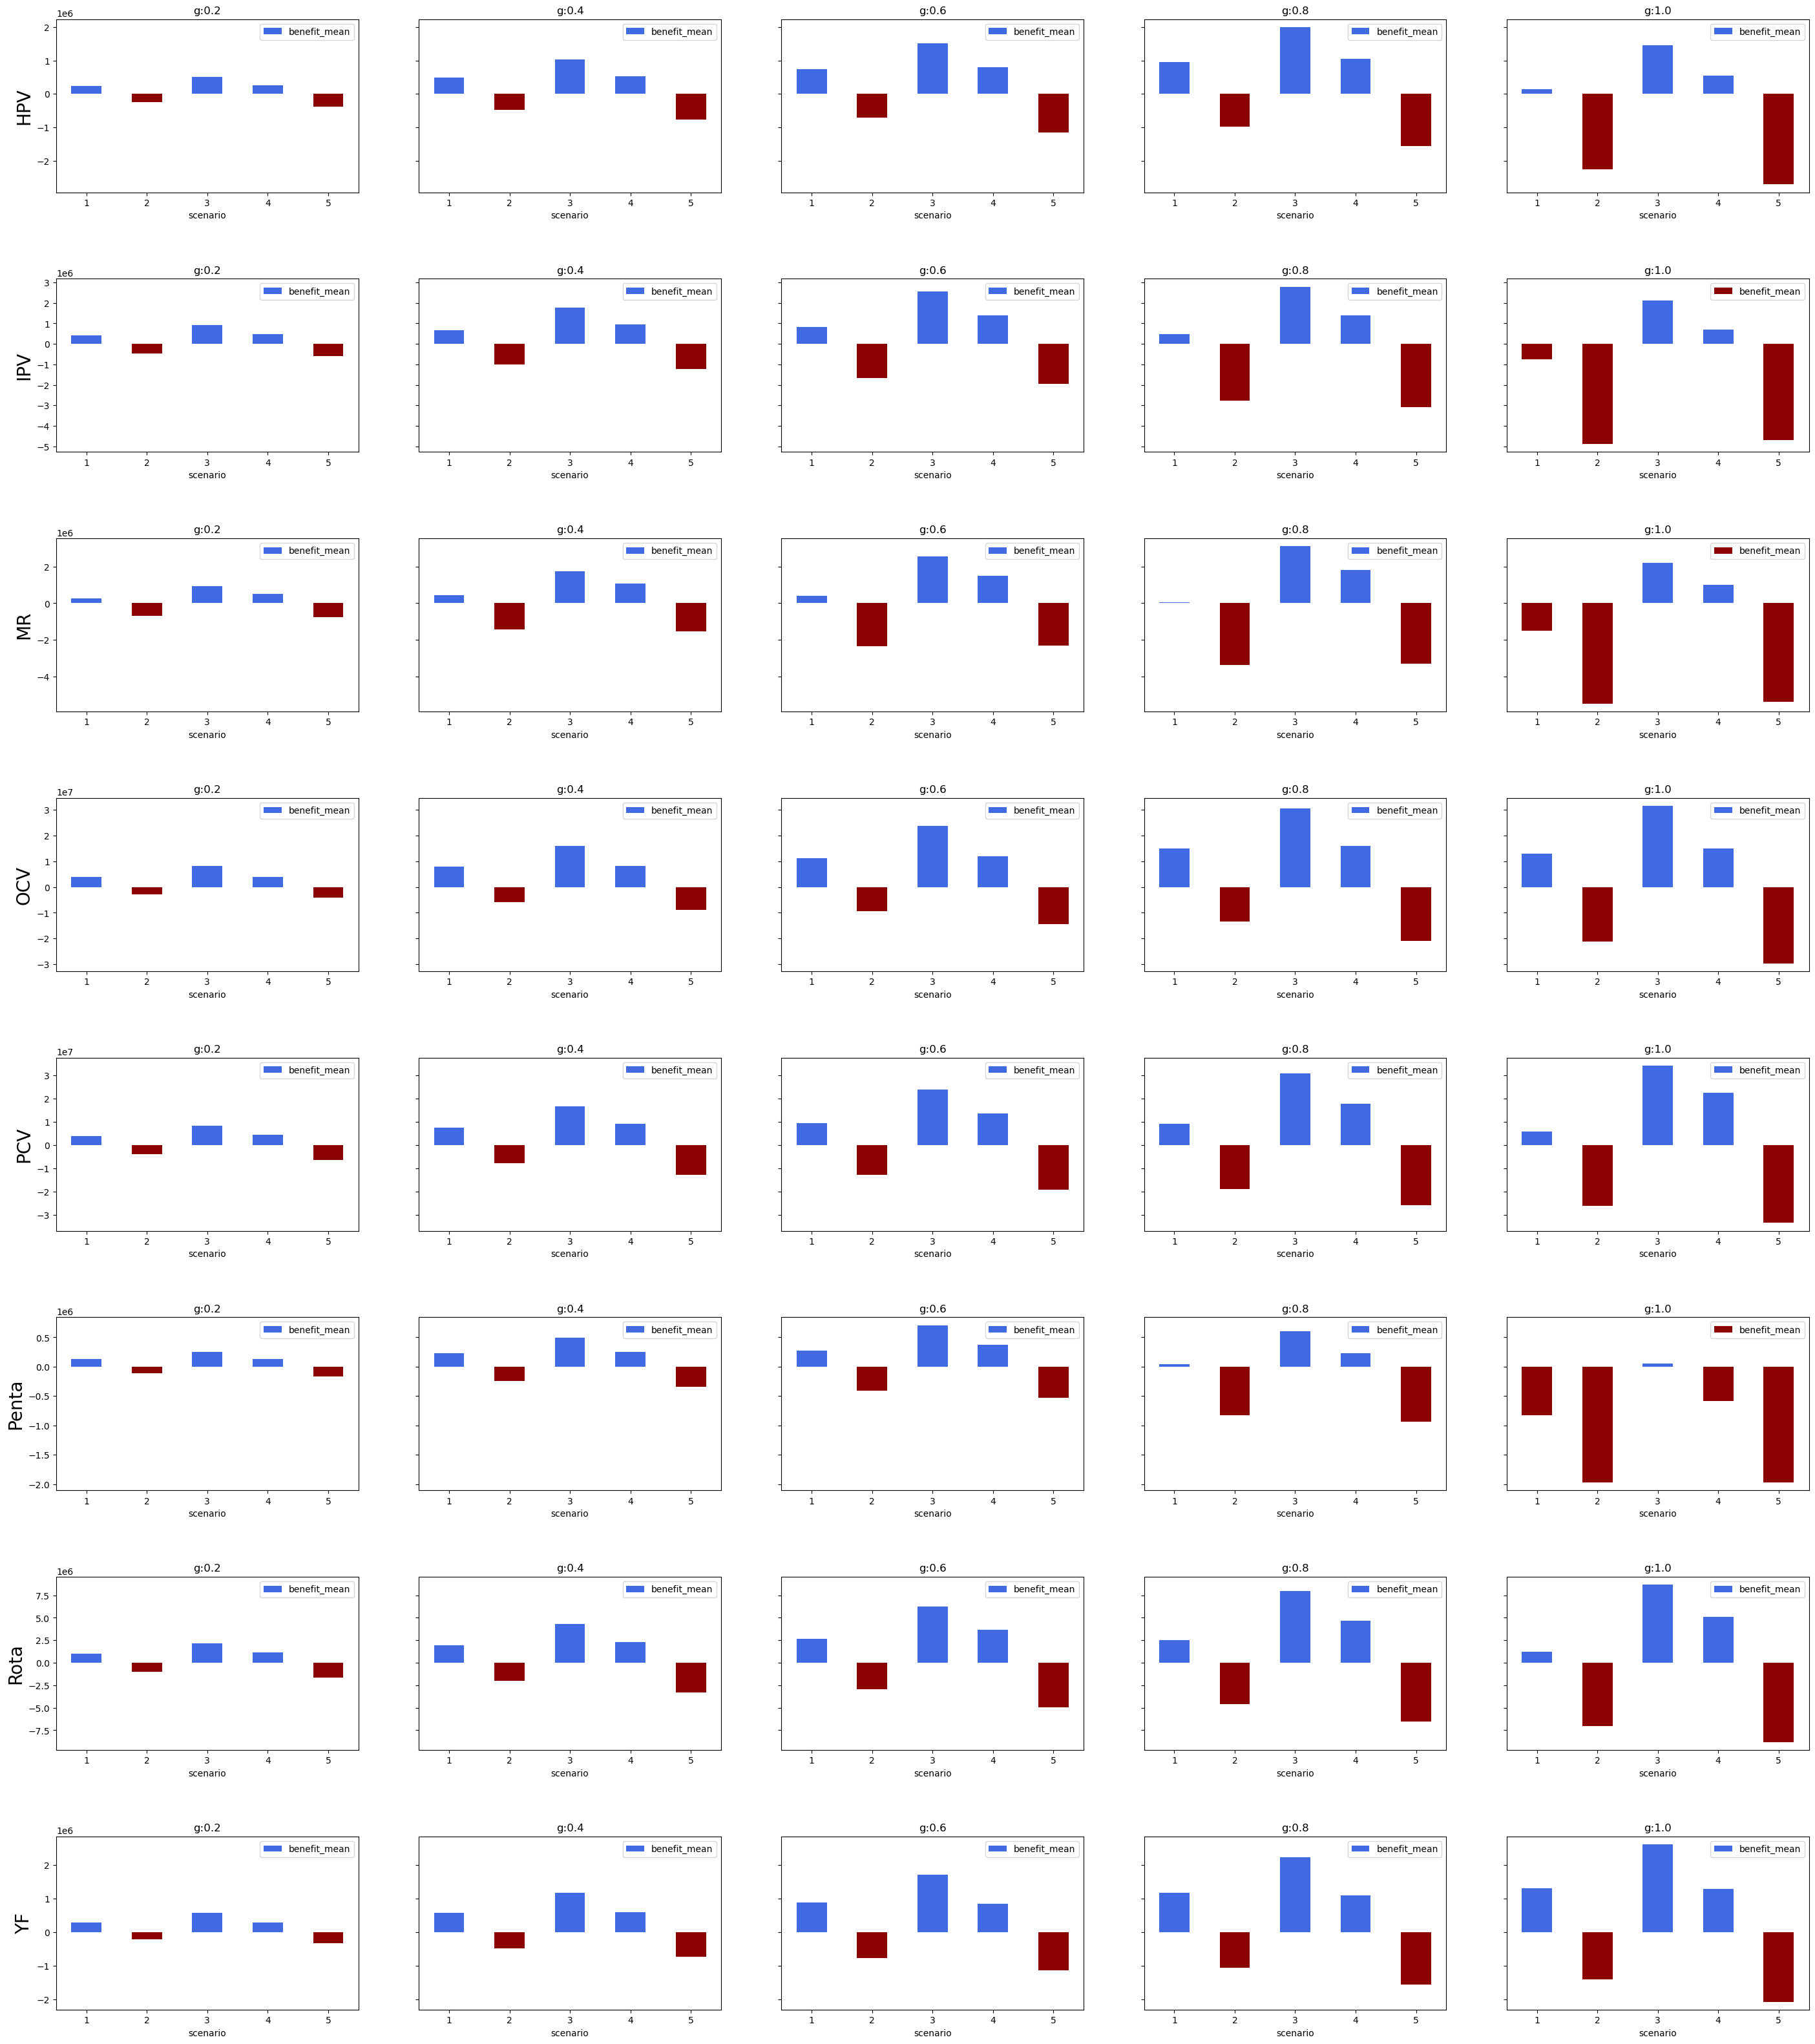

In [20]:
fig, axes = plt.subplots( nrows=len(vaclist), ncols=len(glist)-1, sharey='row',figsize=(35, 40) )

for vc in vaclist:
    for g in glist[1:]:
        df2[(df2['vac']==vc)&(df2['g']==g)].plot(x='scenario',y='benefit_mean', kind='bar', rot=0, ax=axes[vaclist.index(vc)][glist.index(g)-1], color=np.where(df2[(df2['vac']==vc)&(df2['g']==g)].benefit_mean < 0, 'darkred', 'royalblue'))
        axes[vaclist.index(vc)][glist.index(g)-1].set_title(f"g:{g}")
        fig.subplots_adjust(hspace=.5)
    axes[vaclist.index(vc),0].set_ylabel(f'{vc}', rotation=90, size=20)
plt.show()

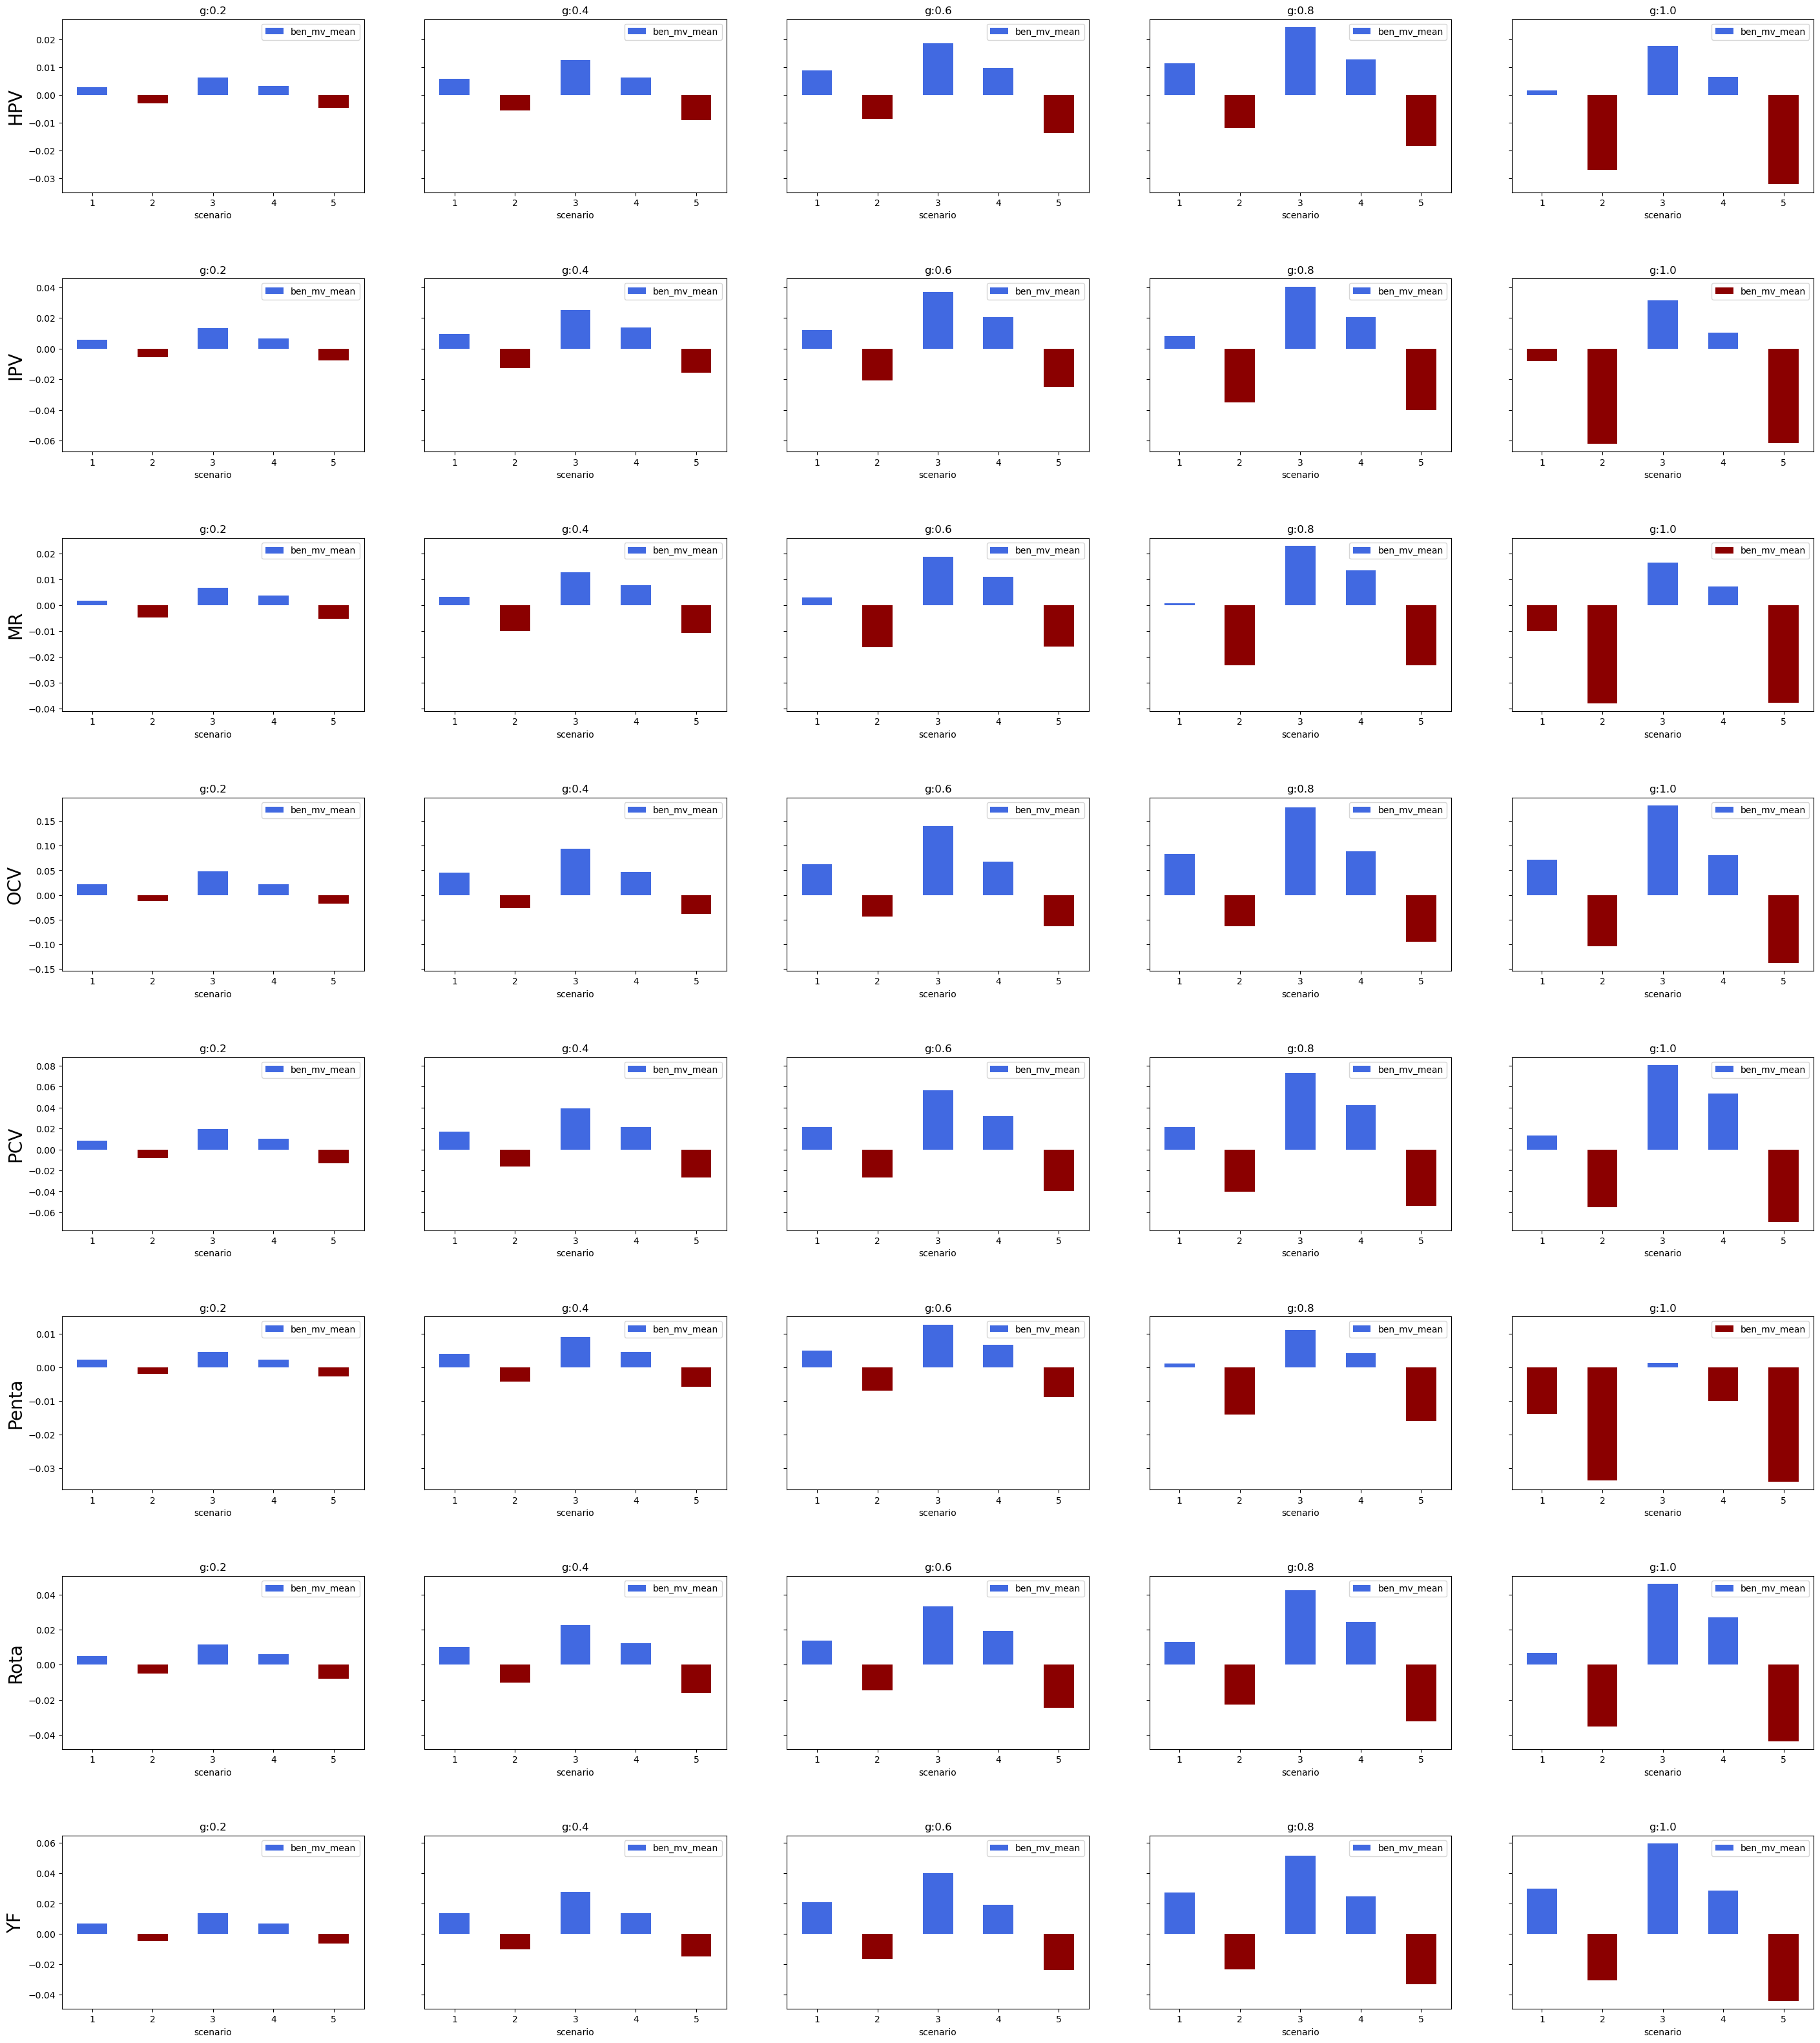

In [21]:
fig, axes = plt.subplots( nrows=len(vaclist), ncols=len(glist)-1, sharey='row',figsize=(35, 40) )

for vc in vaclist:
    for g in glist[1:]:
        df2[(df2['vac']==vc)&(df2['g']==g)].plot(x='scenario',y='ben_mv_mean', kind='bar', rot=0, ax=axes[vaclist.index(vc)][glist.index(g)-1], color=np.where(df2[(df2['vac']==vc)&(df2['g']==g)].benefit_mean < 0, 'darkred', 'royalblue'))
        axes[vaclist.index(vc)][glist.index(g)-1].set_title(f"g:{g}")
        fig.subplots_adjust(hspace=.5)
    axes[vaclist.index(vc),0].set_ylabel(f'{vc}', rotation=90, size=20)
plt.show()

In [22]:
import seaborn as sns

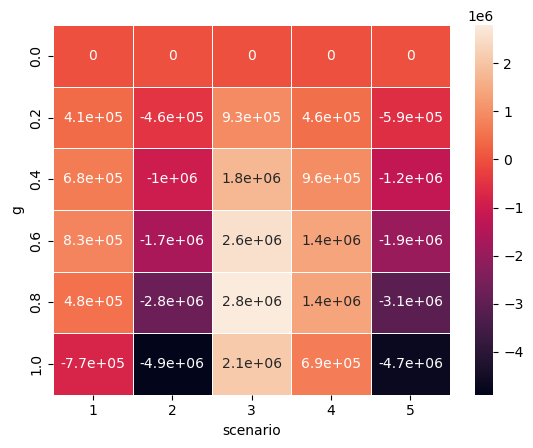

In [23]:
dfint=df2[(df2['vac']=='IPV')].pivot(index="g", columns="scenario", values="benefit_mean")
ax = sns.heatmap(dfint, annot=True, linewidth=.5)


### Table 4. Data used to generate Table 4. Market value and minimum and maximum *absolute* benefits for different vaccines and *g* levels

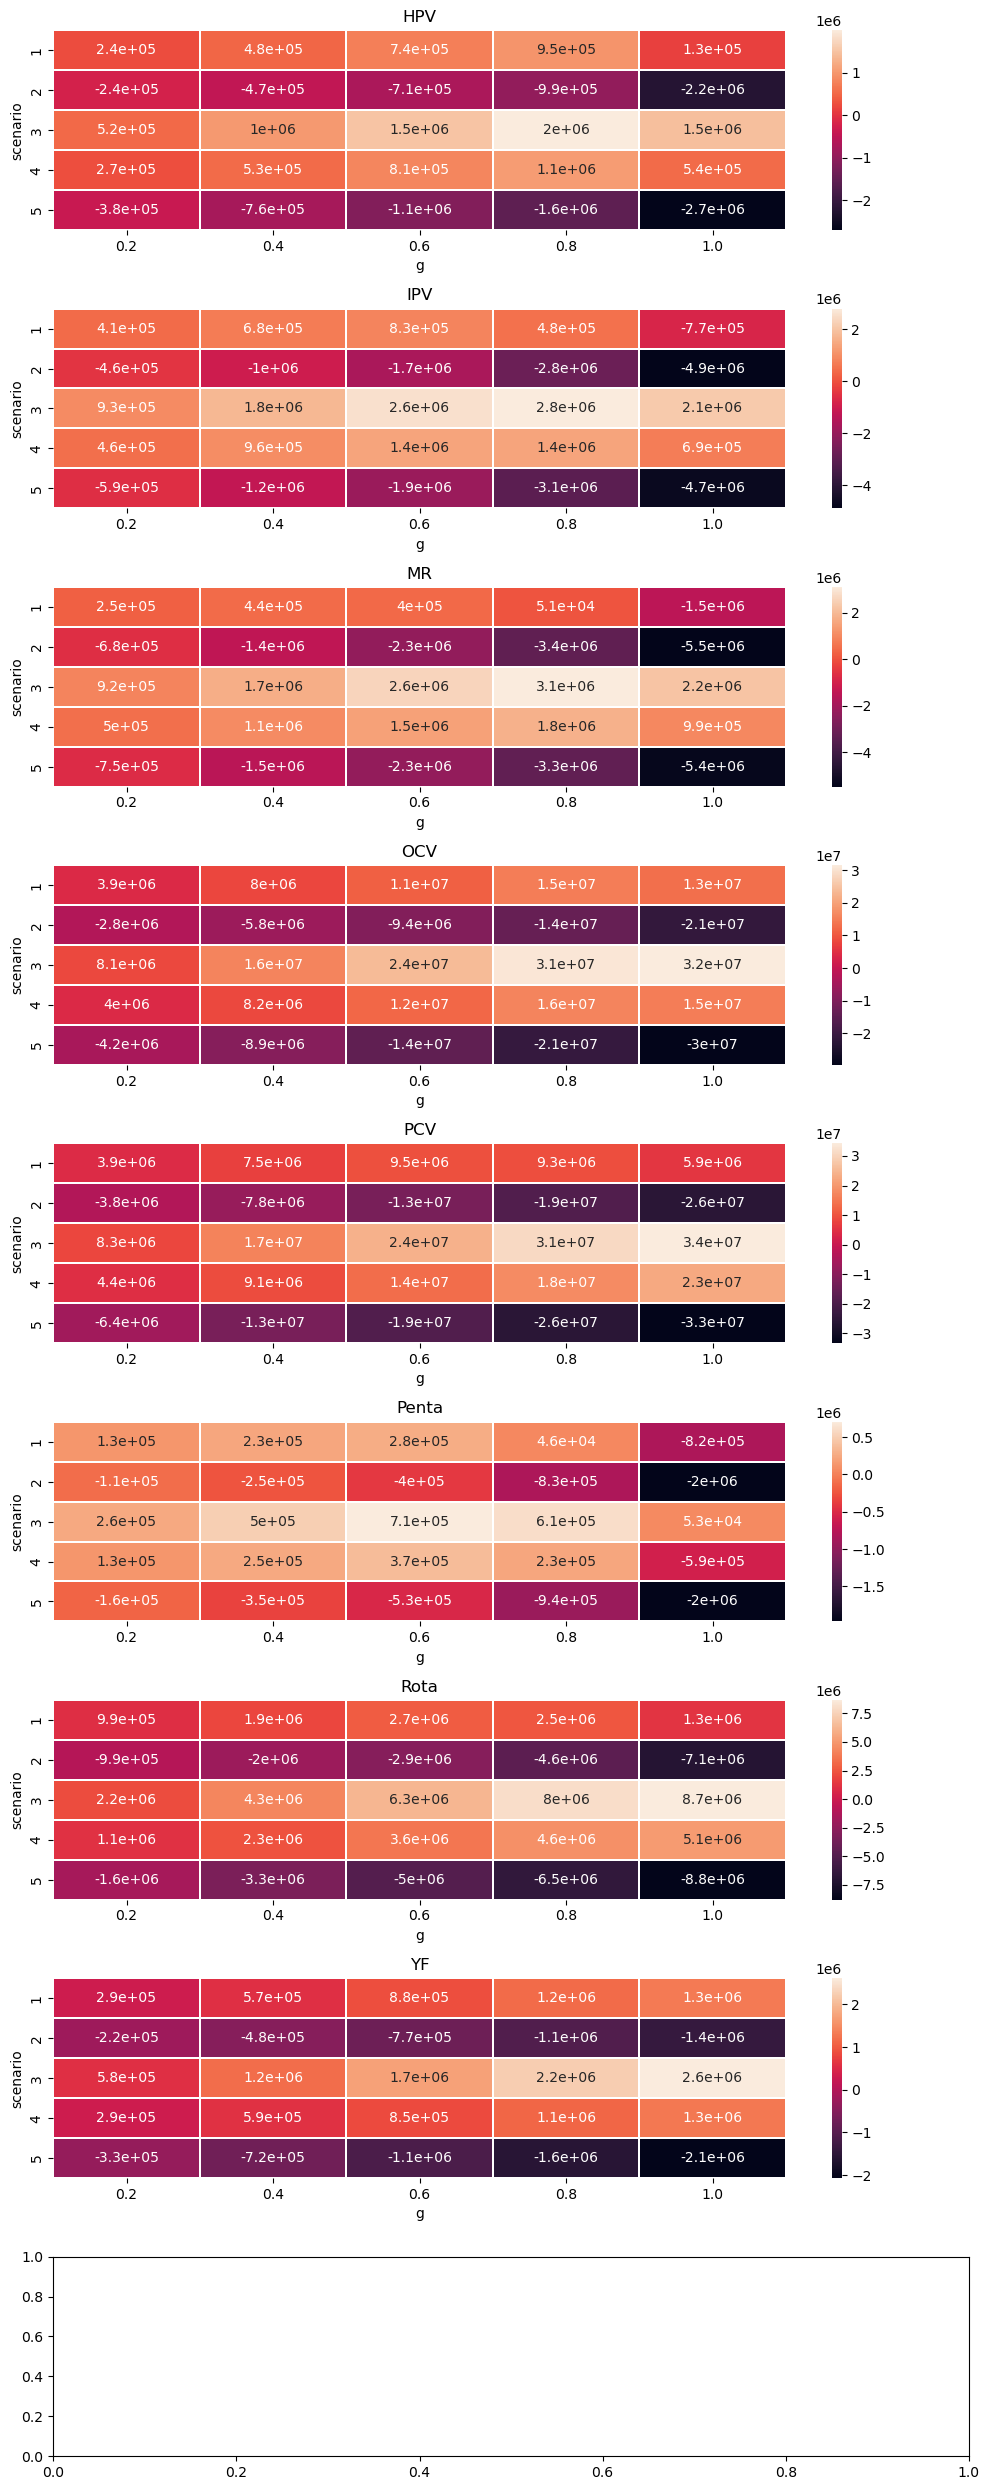

In [24]:
fig, axes = plt.subplots(9, 1, figsize=(10, 25))
 
i=0
for vc in vaclist:      
    dfint=df2[(df2['vac']==vc)&(df2['g']>0.00)].pivot(index="scenario", columns="g", values="benefit_mean")
    sns.heatmap(ax=axes[i], data=dfint,annot=True, linewidth=.1)#, vmin=-3.6e8, vmax=1.2e8)
    axes[i].set_title(vc)
    i=i+1
plt.tight_layout()
plt.show()

   
    


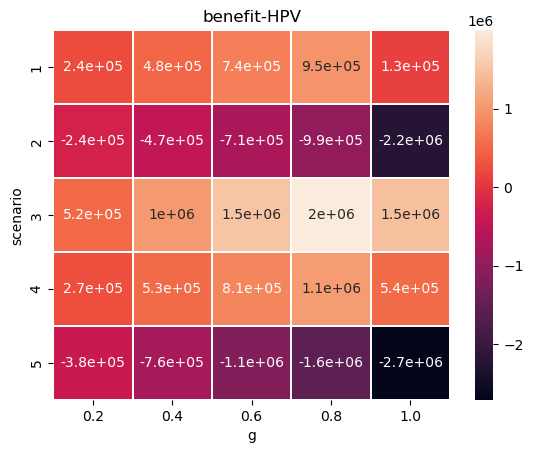

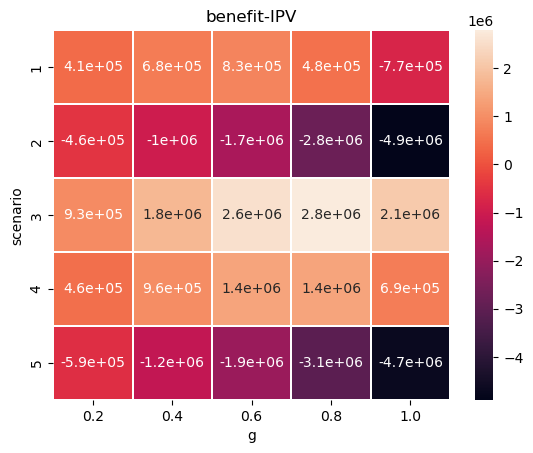

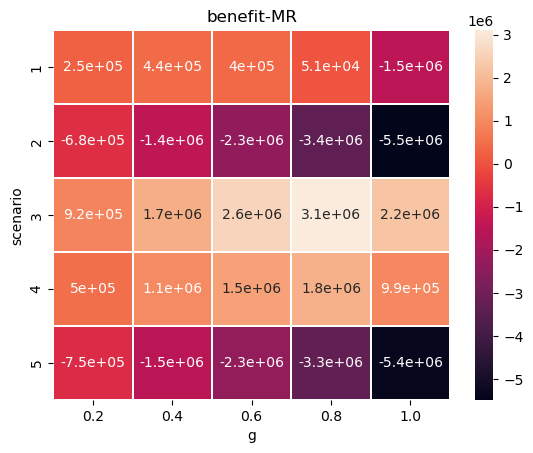

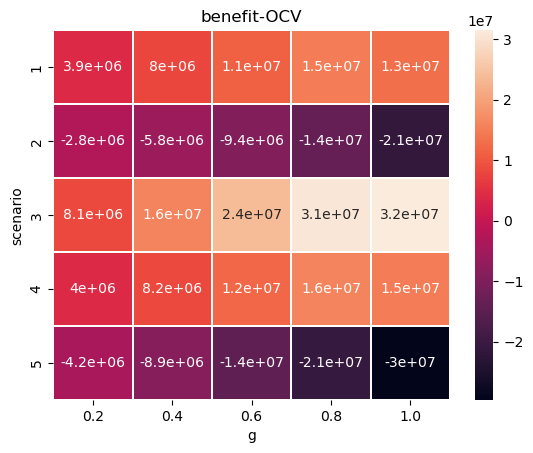

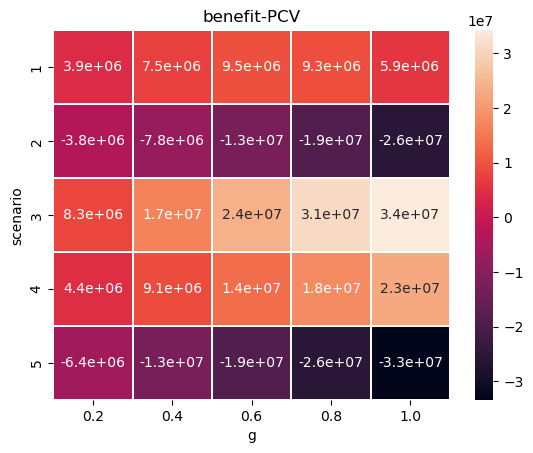

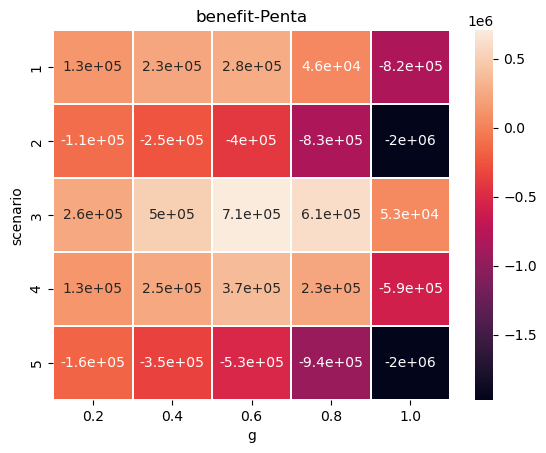

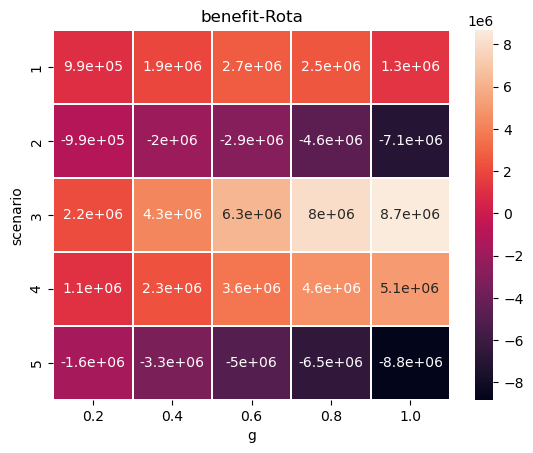

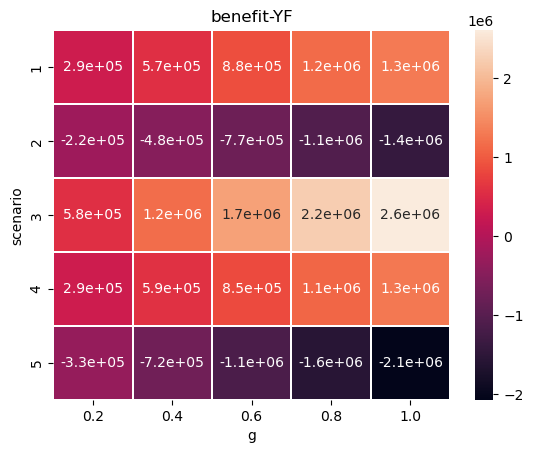

In [25]:
#fig, axes = plt.subplots(1, 1, figsize=(15, 10))
 
for vc in vaclist:      
    dfint=df2[(df2['vac']==vc)&(df2['g']>0.00)].pivot(index="scenario", columns="g", values="benefit_mean")
    ax=sns.heatmap(data=dfint,annot=True, linewidth=.1)#, vmin=-3.6e8, vmax=1.2e8)
    plt.title('benefit-'+ vc)
    #plt.tight_layout()
    plt.show()   
   


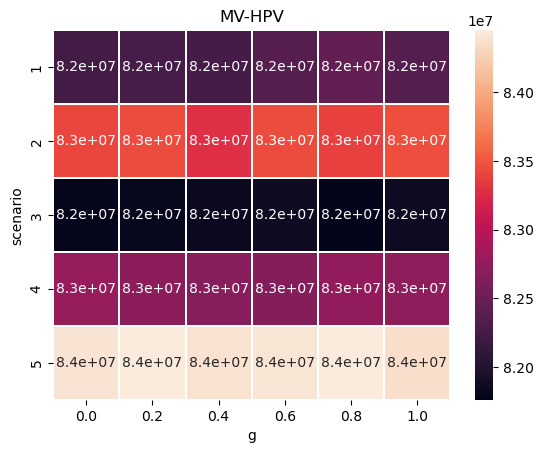

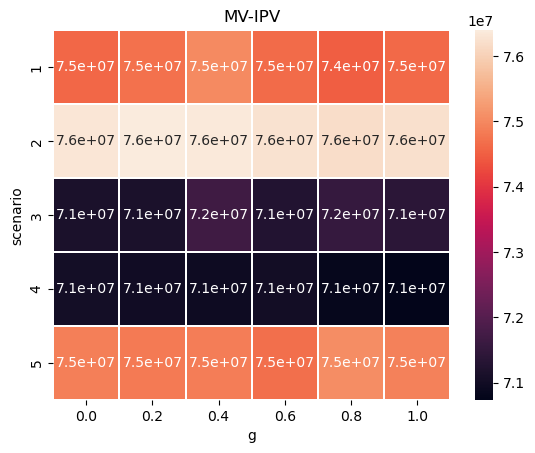

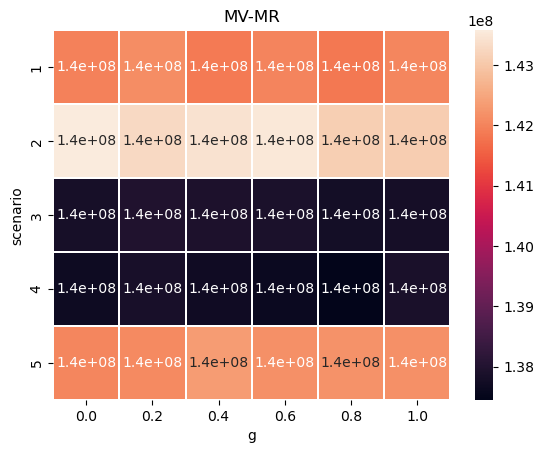

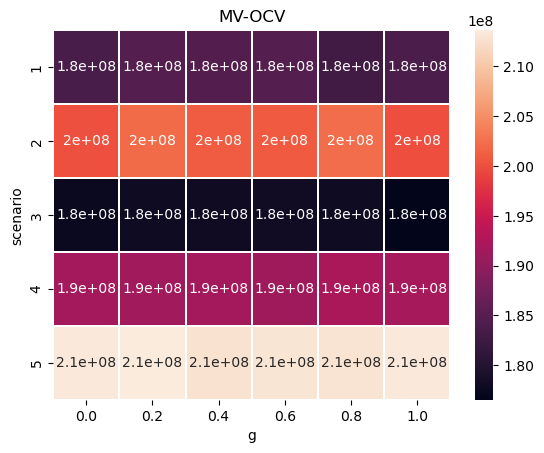

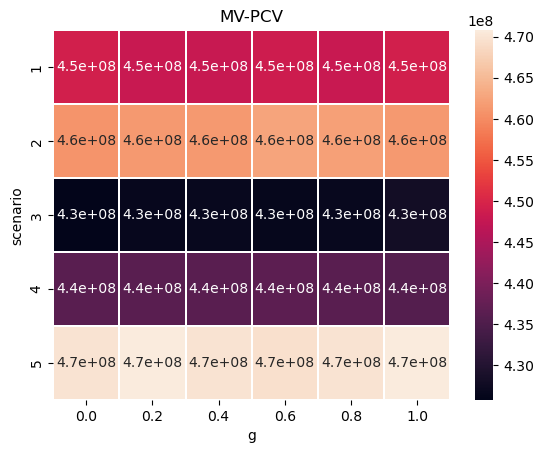

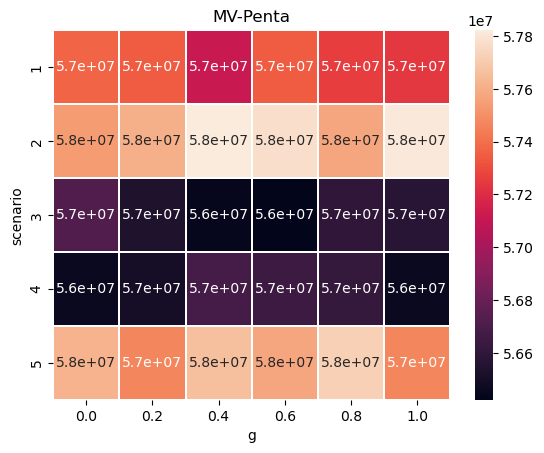

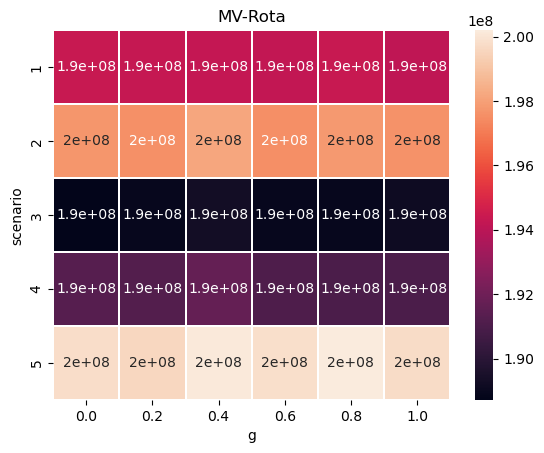

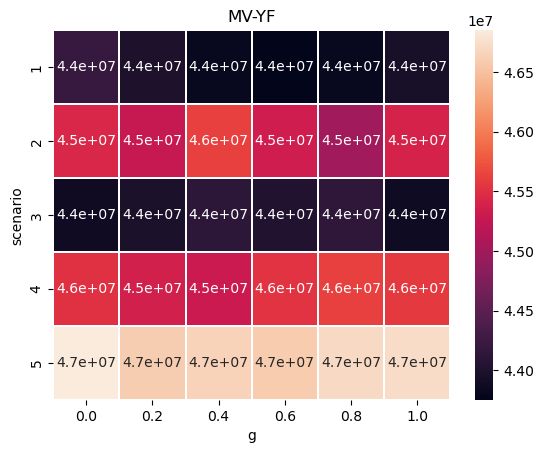

In [26]:
#fig, axes = plt.subplots(1, 1, figsize=(15, 10))
 
for vc in vaclist:      
    dfint=df2[(df2['vac']==vc)&(df2['g']>=0.00)].pivot(index="scenario", columns="g", values="marketvalue_o_mean")
    ax=sns.heatmap(data=dfint,annot=True, linewidth=.1)#, vmin=-3.6e8, vmax=1.2e8)
    plt.title('MV-'+ vc)
    #plt.tight_layout()
    plt.show()   
   

### Computing market values for each vaccine

In [27]:
df2.groupby(['vac'], as_index=False).agg({'marketvalue_o_mean':['mean']})                         



,vac,marketvalue_o_mean
,,mean
0,HPV,8.293e+07
1,IPV,7.362e+07
2,MR,1.406e+08
3,OCV,1.935e+08
4,PCV,4.486e+08
5,Penta,5.713e+07
6,Rota,1.944e+08
7,YF,4.509e+07


### Table 5.  Data used for preparing Table 5. Impact as a fraction of the vaccine maket value at benchmark level of *g*. (data presented as ratios. The paper presents data Table 5 as percentages)

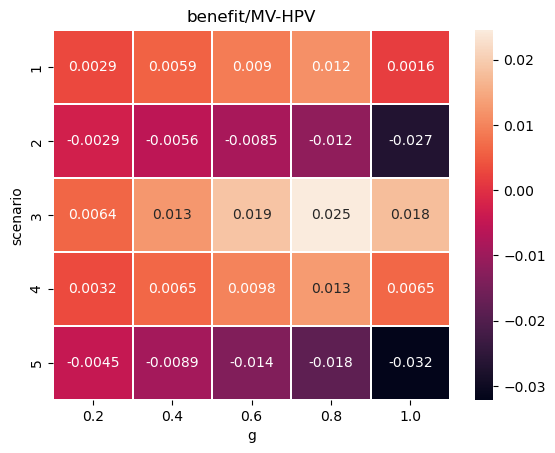

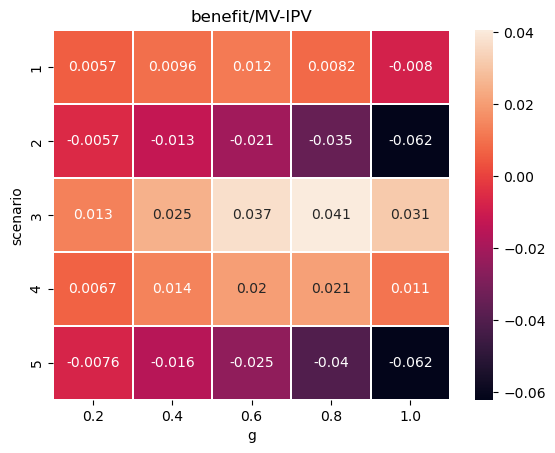

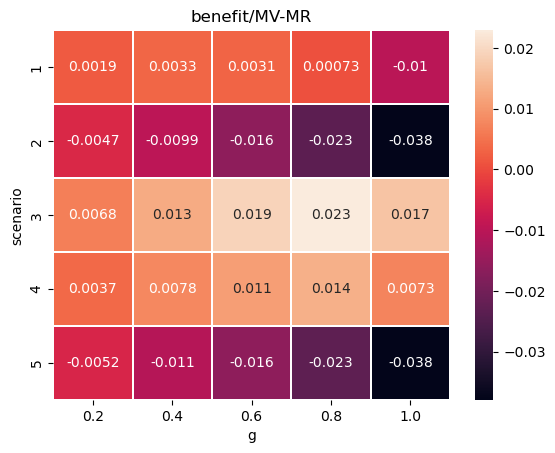

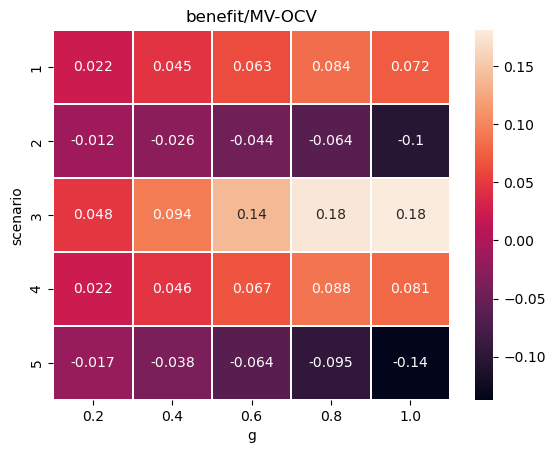

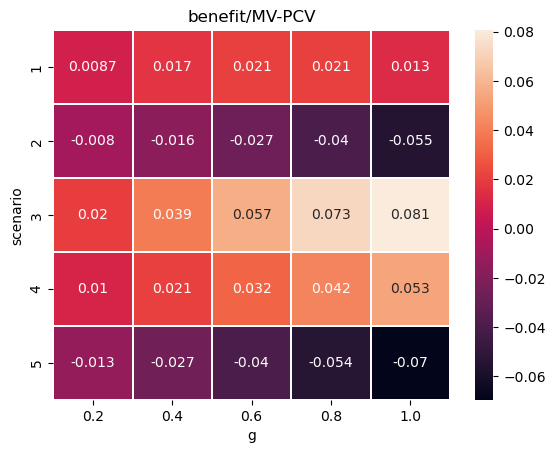

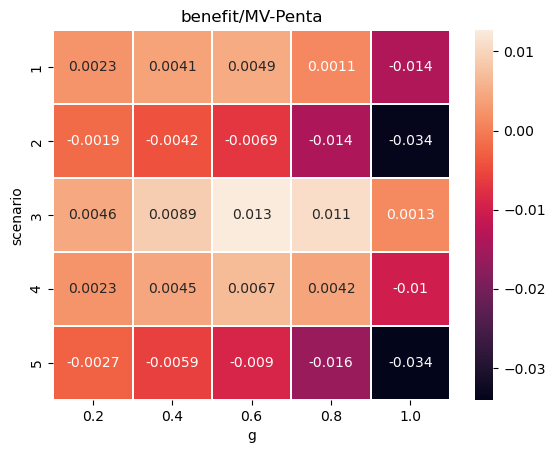

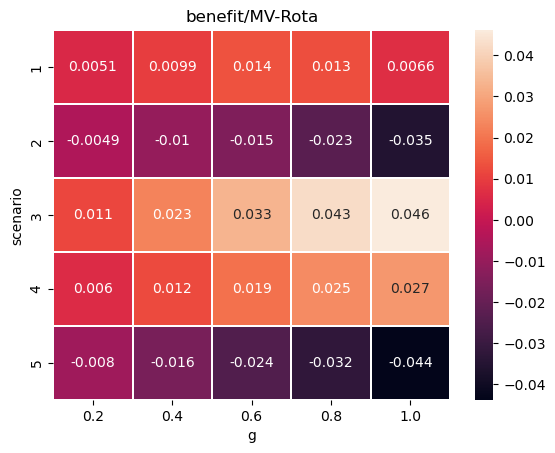

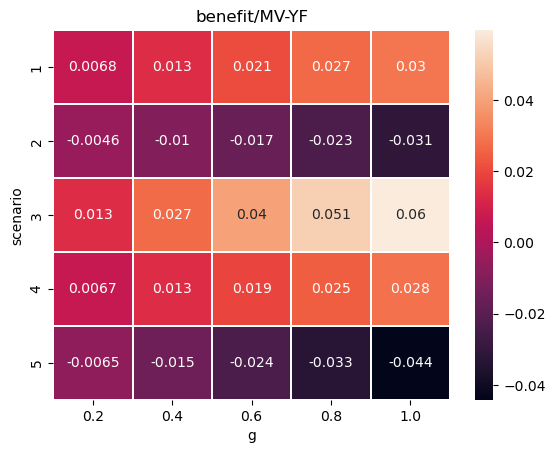

In [28]:
for vc in vaclist:      
    dfint=df2[(df2['vac']==vc)&(df2['g']>0.00)].pivot(index="scenario", columns="g", values="ben_mv_mean")
    ax=sns.heatmap(data=dfint,annot=True, linewidth=.1)#, vmin=-3.6e8, vmax=1.2e8)
    plt.title('benefit/MV-'+ vc)
    #plt.tight_layout()
    plt.show()   
   


### Figure 3 plots ( $\delta_i^j$)
Average net change in profit for vaccine $j$, under profit scenario $i$, for various supply goal levels, $g$.

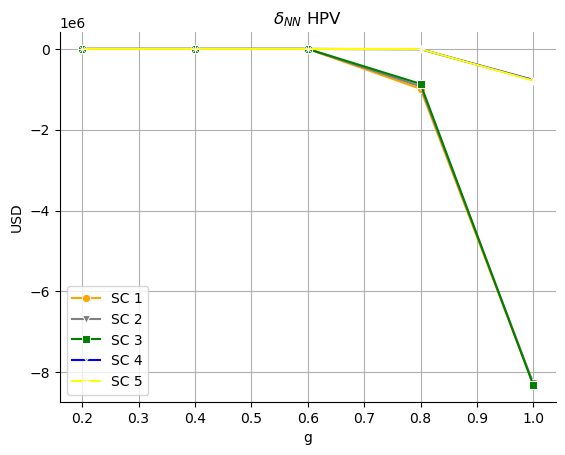

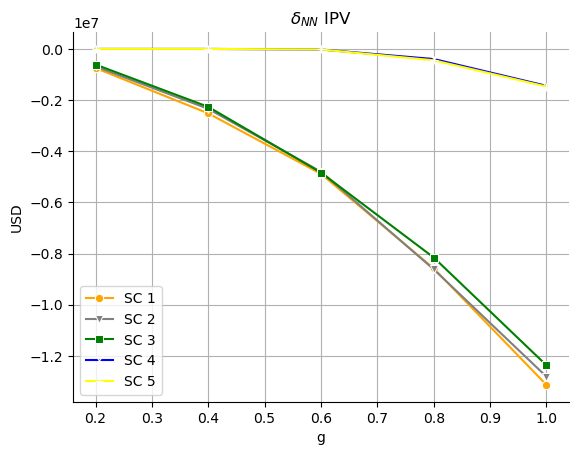

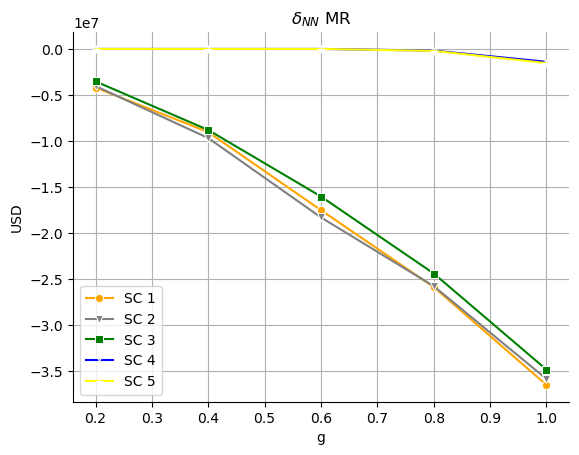

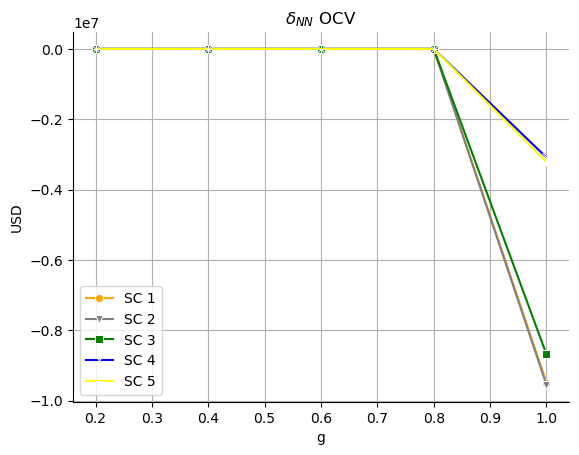

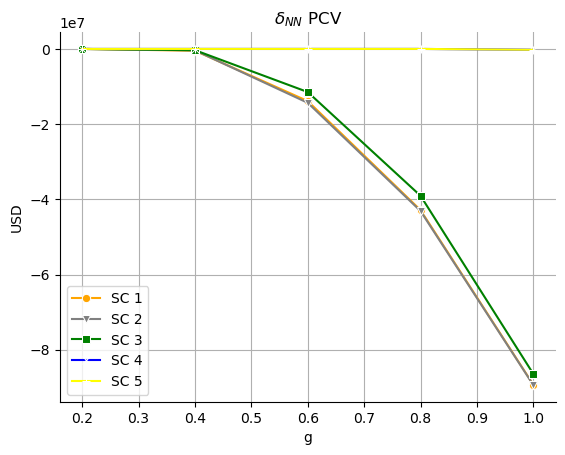

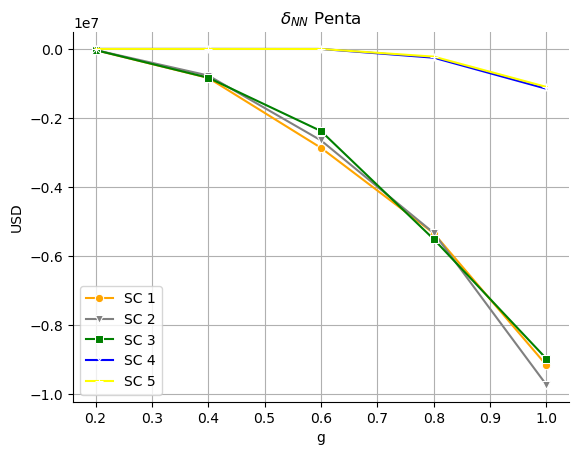

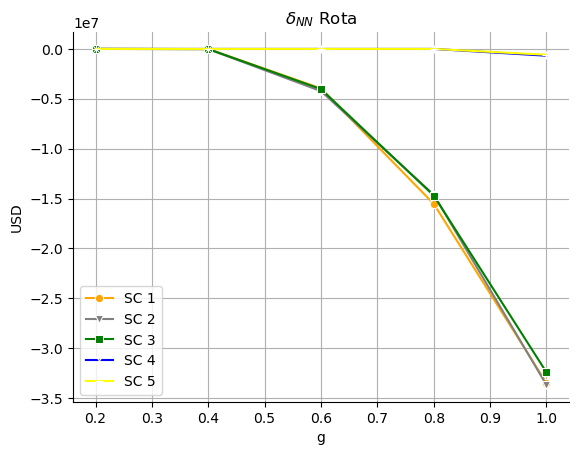

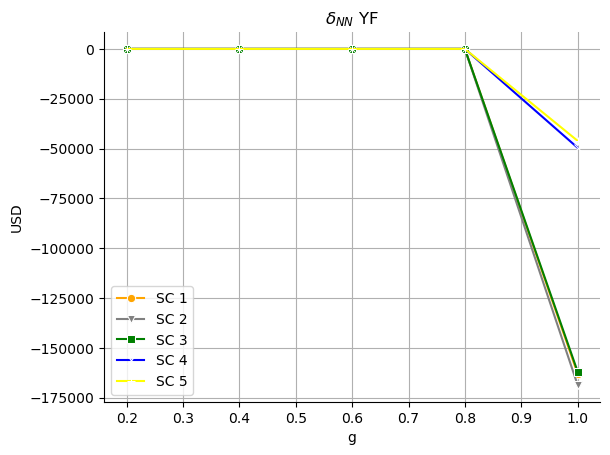

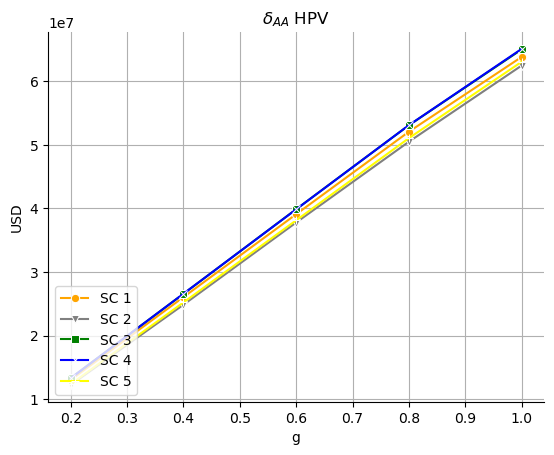

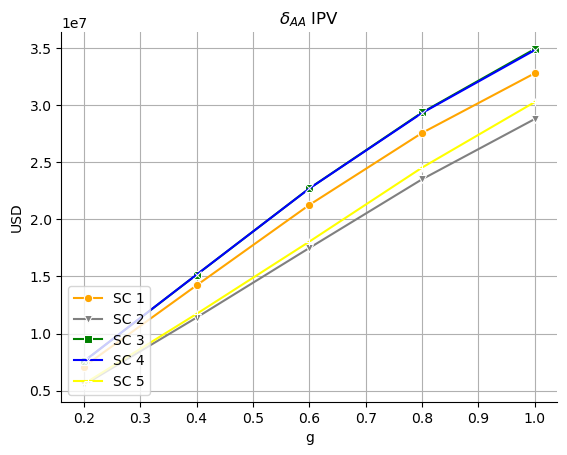

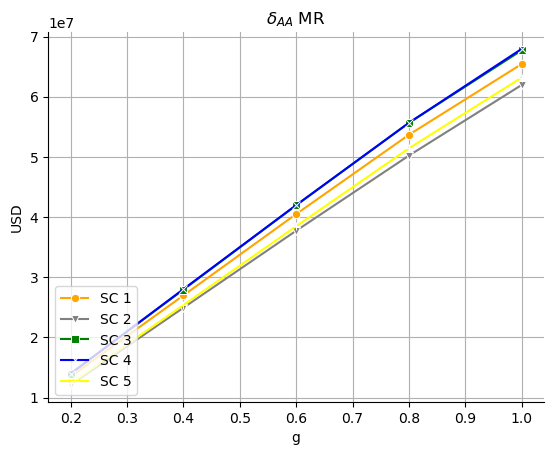

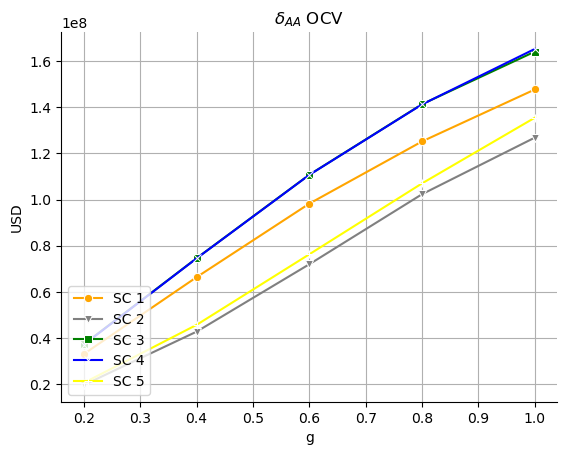

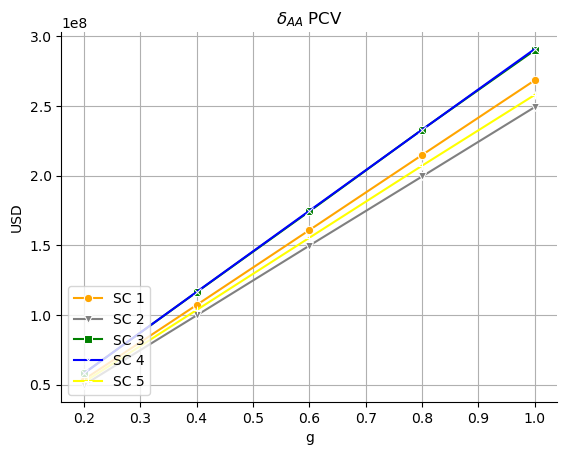

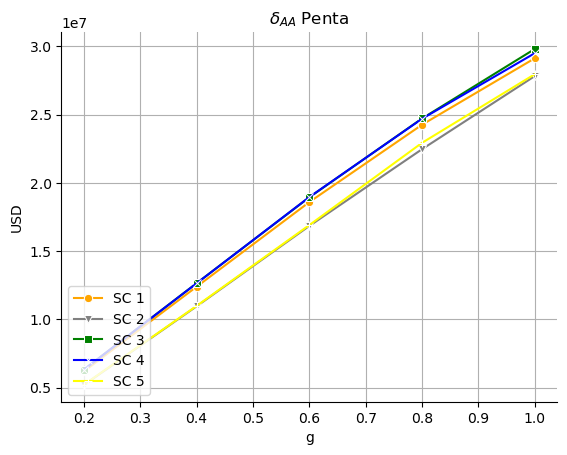

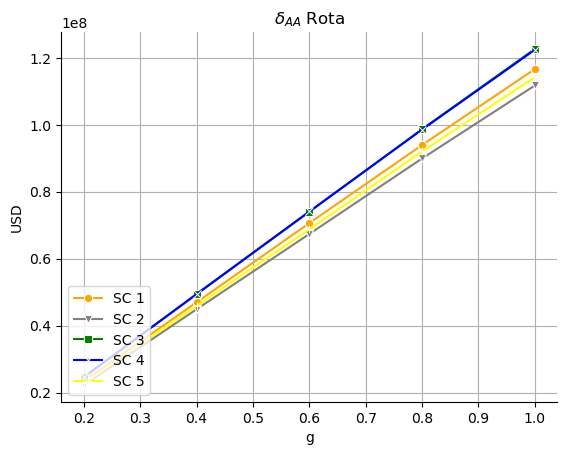

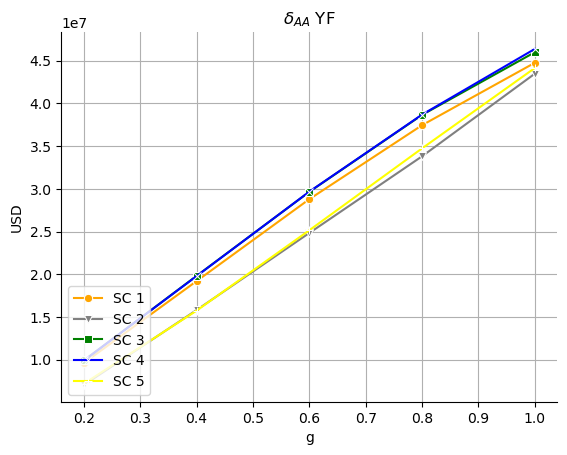

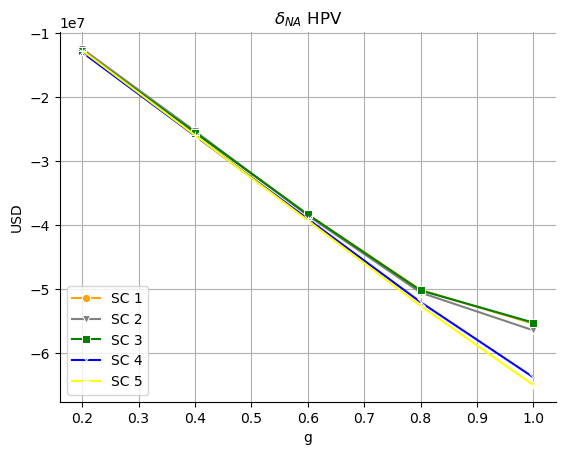

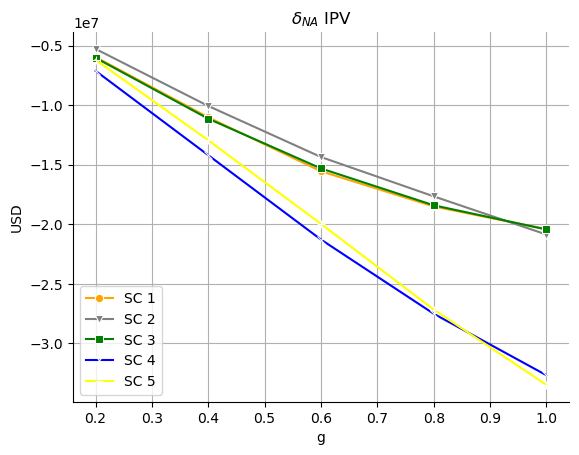

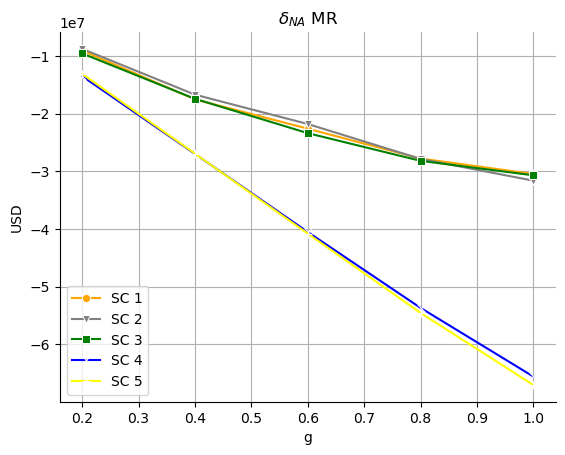

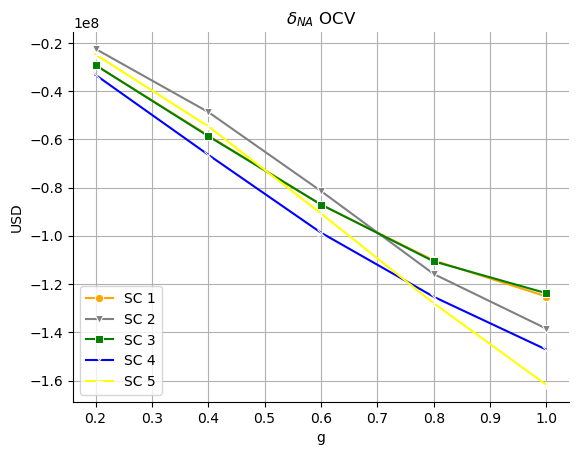

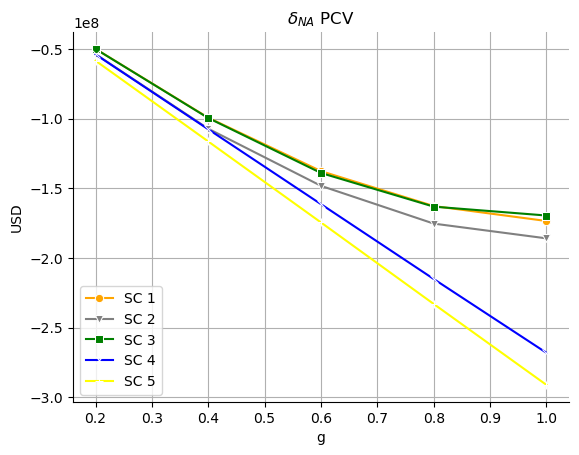

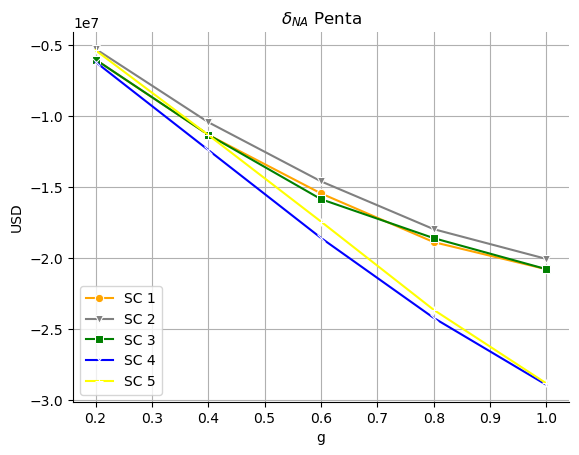

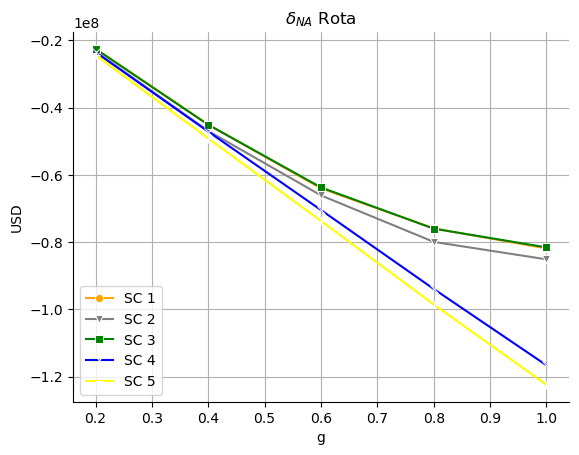

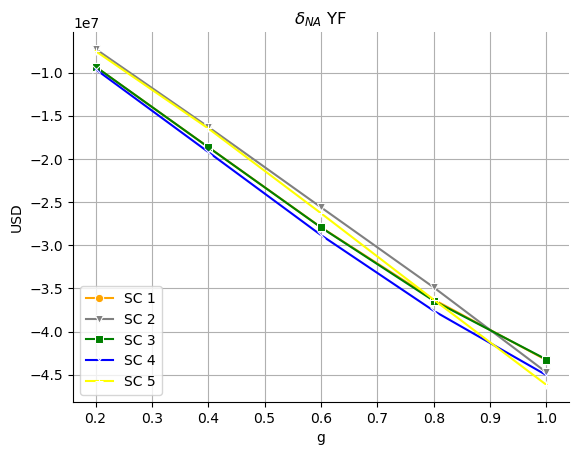

In [29]:
colorlist=['red','orange','gray','green','blue','yellow','purple']
mrklist=['p','o','v','s','x','+','d']

# plotting a figure for all pDdif_mean for all vaccines ($\delta_{NN}$)

for vc in vaclist:
    dfref=df2[(df2['vac']==vc)&(df2['g']>0.00)]
    for ii in dfref.scenario.unique():
        sns.lineplot(x='g',y='pDdif_mean', data=dfref[dfref['scenario']==ii],marker=mrklist[ii], color=colorlist[ii], label='SC '+str(ii))
        plt.title(r'$\delta_{NN}$ '+str(vc))
        plt.xlabel('g')
        plt.ylabel('USD')
 
    # Add a legend
    plt.legend(loc='lower left')
 
    # Add a grid
    plt.grid(True)
 
    # Remove the top and right spines
    sns.despine()
 
    # Show the plot
    plt.show()

# plotting a figure for all pOdif_mean for all vaccines ($\delta_{AA}}$)

for vc in vaclist:
    dfref=df2[(df2['vac']==vc)&(df2['g']>0.00)]
    for ii in dfref.scenario.unique():
        sns.lineplot(x='g',y='pOdif_mean', data=dfref[dfref['scenario']==ii],marker=mrklist[ii], color=colorlist[ii], label='SC '+str(ii))
        plt.title(r'$\delta_{AA}$ '+str(vc))
        plt.xlabel('g')
        plt.ylabel('USD')
 
    # Add a legend
    plt.legend(loc='lower left')
 
    # Add a grid
    plt.grid(True)
 
    # Remove the top and right spines
    sns.despine()
 
    # Show the plot
    plt.show()

    
# plotting a figure for all pTdif_mean for all vaccines ($\delta_{NA}$)

for vc in vaclist:
    dfref=df2[(df2['vac']==vc)&(df2['g']>0.00)]
    for ii in dfref.scenario.unique():
        sns.lineplot(x='g',y='pTdif_mean', data=dfref[dfref['scenario']==ii],marker=mrklist[ii], color=colorlist[ii], label='SC '+str(ii))
        plt.title(r'$\delta_{NA}$ '+str(vc))
        plt.xlabel('g')
        plt.ylabel('USD')
 
    # Add a legend
    plt.legend(loc='lower left')
 
    # Add a grid
    plt.grid(True)
 
    # Remove the top and right spines
    sns.despine()
 
    # Show the plot
    plt.show()

## Figure 4 plots ( $\text{benefit}_i^j$)
Average net benefit from sales of vaccine $j$ across all
procurement interactions, for various supply goal levels, $g$

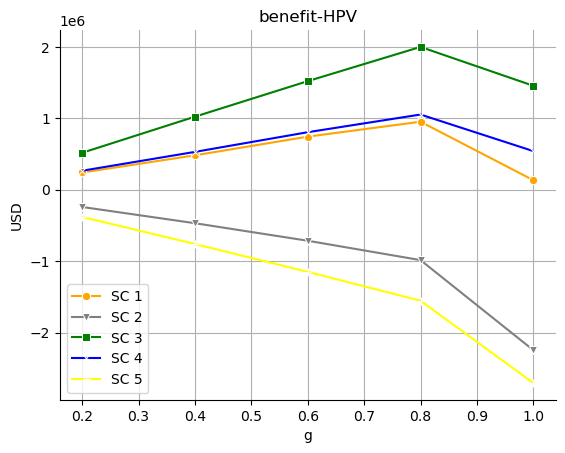

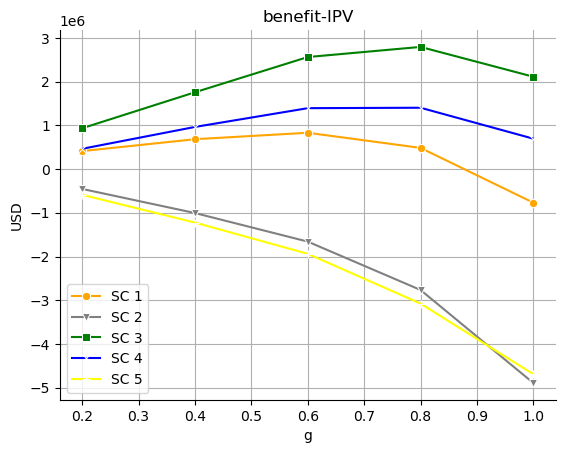

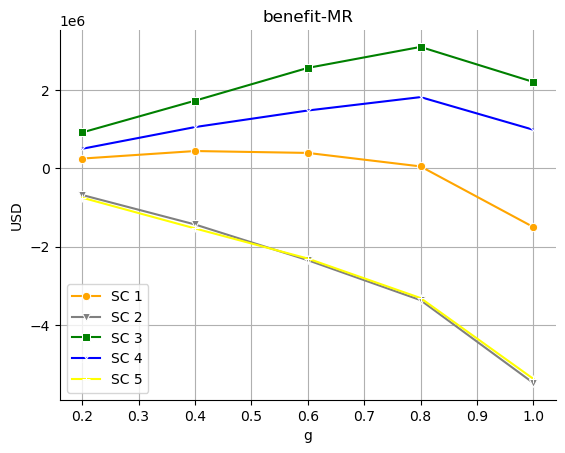

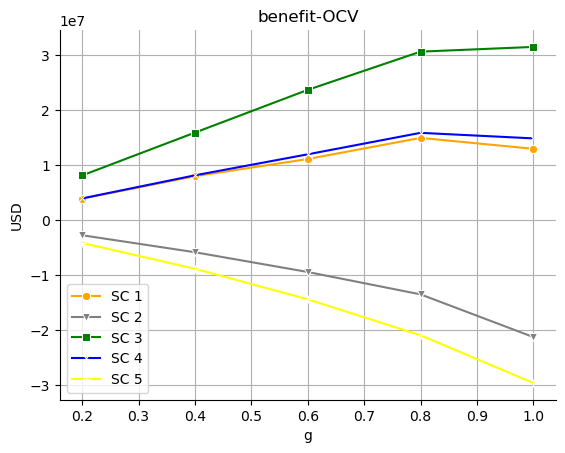

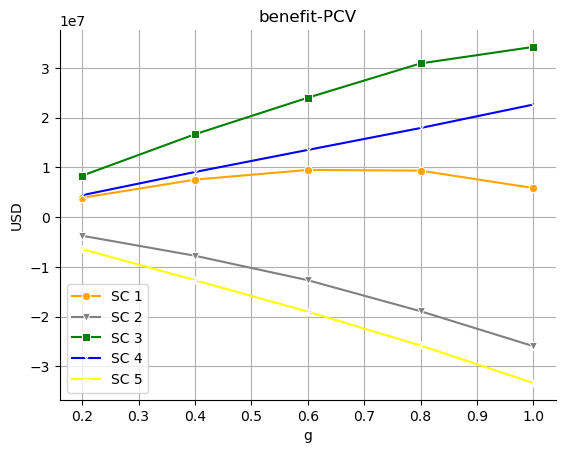

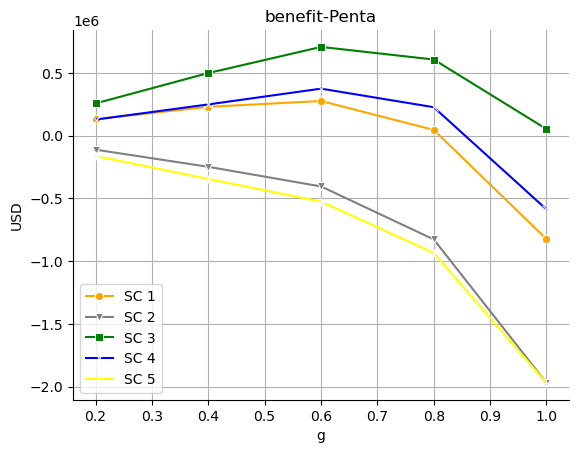

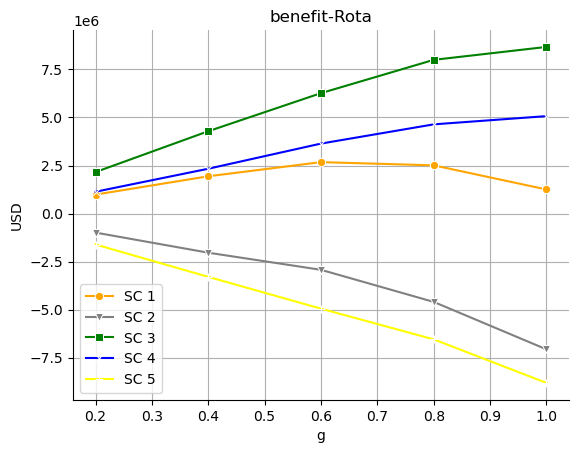

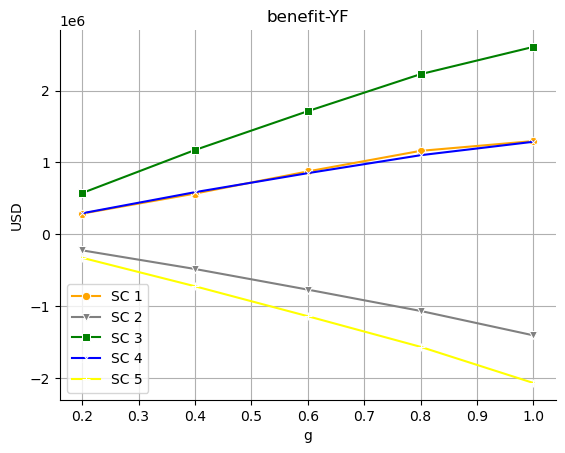

In [30]:
colorlist=['red','orange','gray','green','blue','yellow','purple']
mrklist=['p','o','v','s','x','+','d']
for vc in vaclist:
    dfref=df2[(df2['vac']==vc)&(df2['g']>0.00)]
    for ii in dfref.scenario.unique():
        sns.lineplot(x='g',y='benefit_mean', data=dfref[dfref['scenario']==ii],marker=mrklist[ii], color=colorlist[ii], label='SC '+str(ii))
        plt.title('benefit-'+str(vc))
        plt.xlabel('g')
        plt.ylabel('USD')
 
    # Add a legend
    plt.legend(loc='lower left')
 
    # Add a grid
    plt.grid(True)
 
    # Remove the top and right spines
    sns.despine()
 
    # Show the plot
    plt.show()


## Figure 5 ($\frac{\text{benefit}}{MV}$)

Ratio between average benefit over market value at benchmark scenario (at $g = 0$) per
vaccine, scenario, and $g$

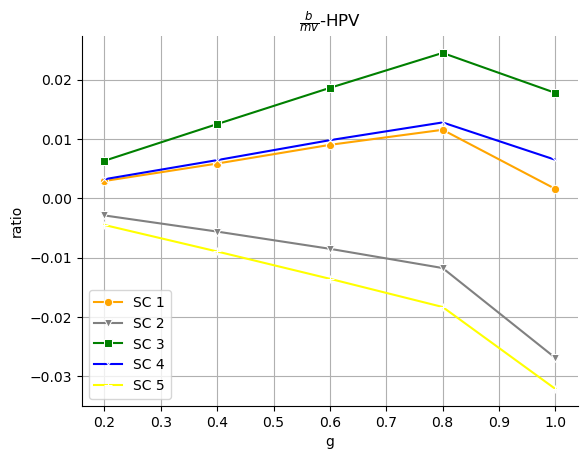

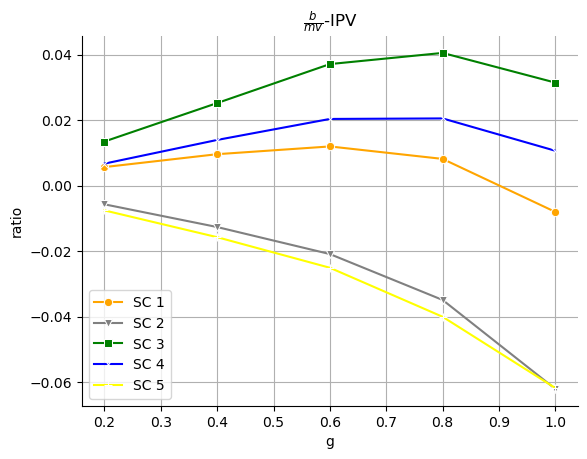

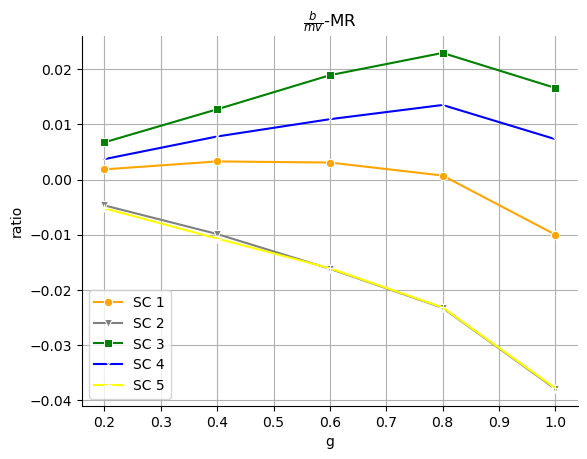

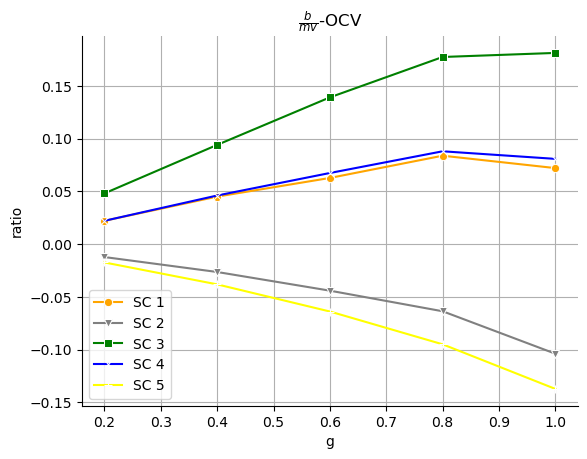

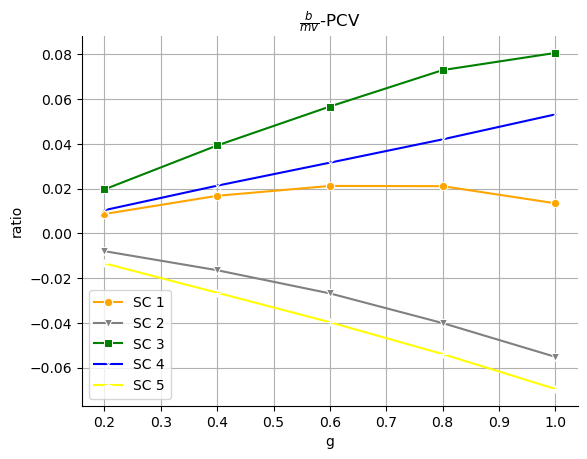

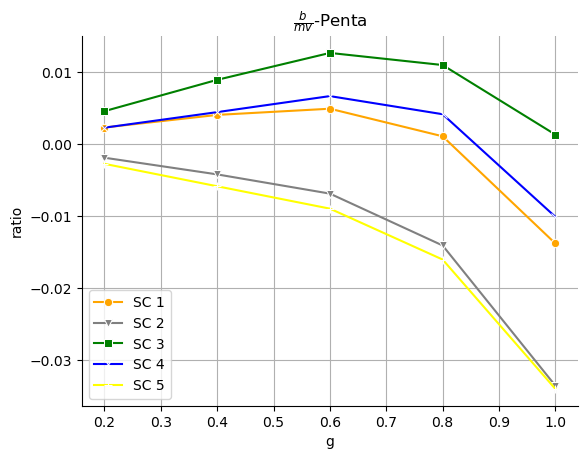

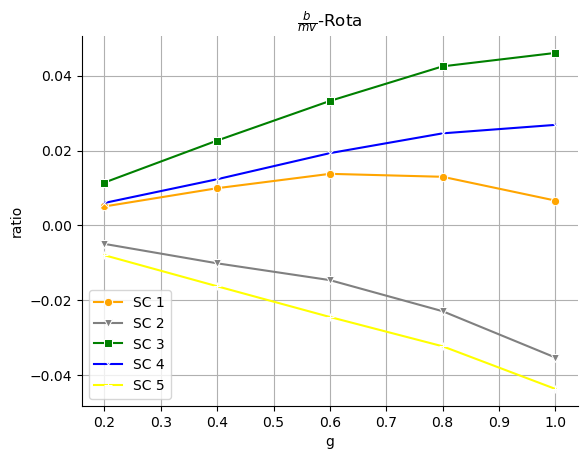

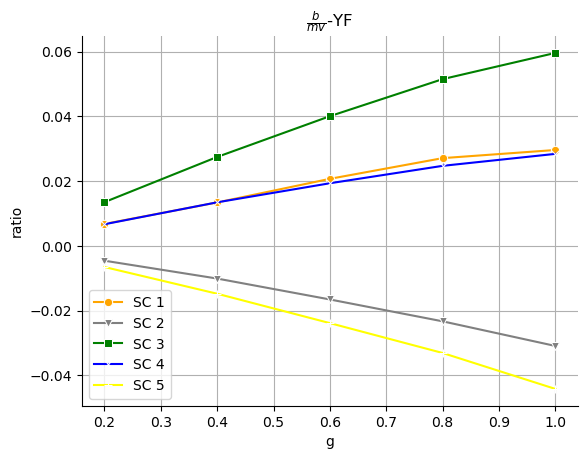

In [31]:
colorlist=['red','orange','gray','green','blue','yellow','purple']
mrklist=['p','o','v','s','x','+','d']
for vc in vaclist:
    dfref=df2[(df2['vac']==vc)&(df2['g']>0.00)]
    for ii in dfref.scenario.unique():
        sns.lineplot(x='g',y='ben_mv_mean', data=dfref[dfref['scenario']==ii],marker=mrklist[ii], color=colorlist[ii], label='SC '+str(ii))
        plt.title(r'$\frac{b}{mv}$-'+str(vc))
        plt.xlabel('g')
        plt.ylabel('ratio')
 
    # Add a legend
    plt.legend(loc='lower left')
 
    # Add a grid
    plt.grid(True)
 
    # Remove the top and right spines
    sns.despine()
 
    # Show the plot
    plt.show()


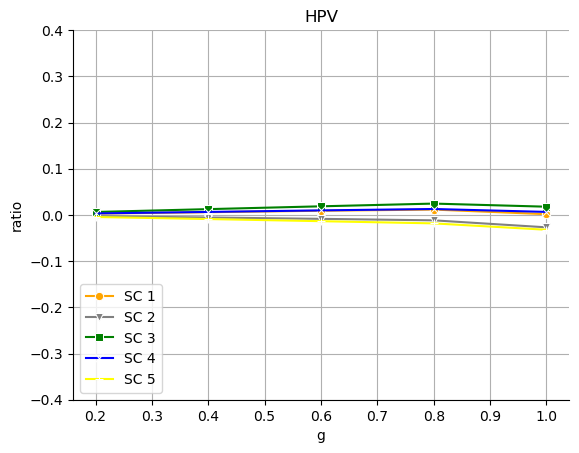

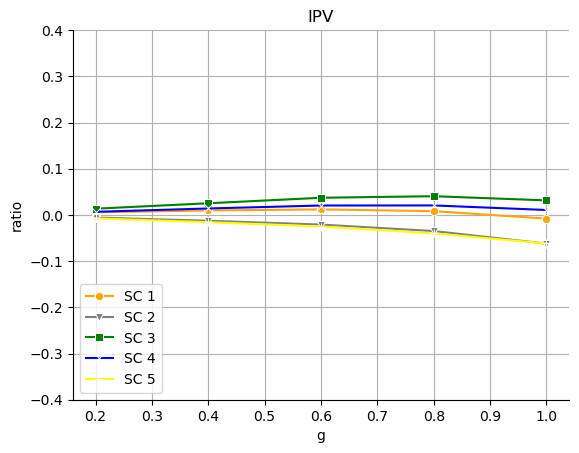

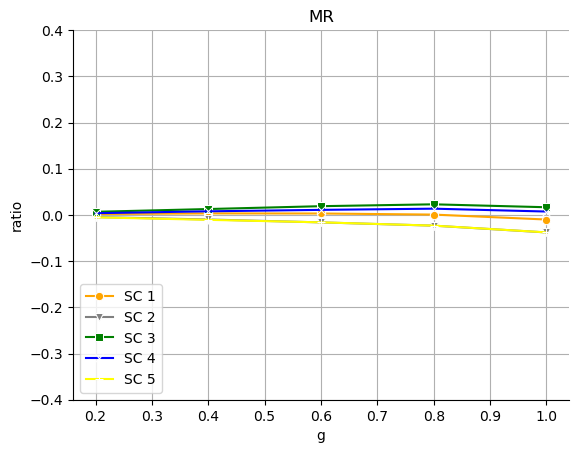

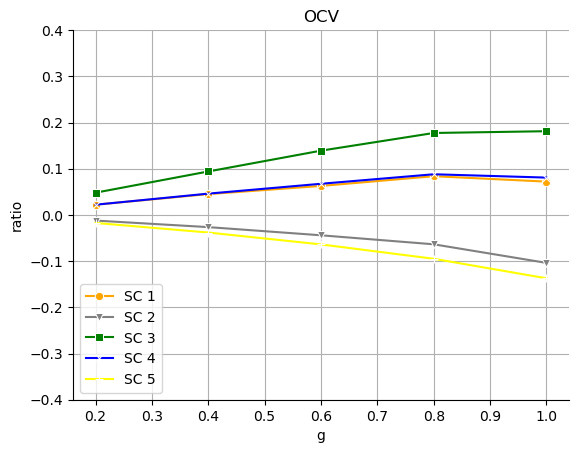

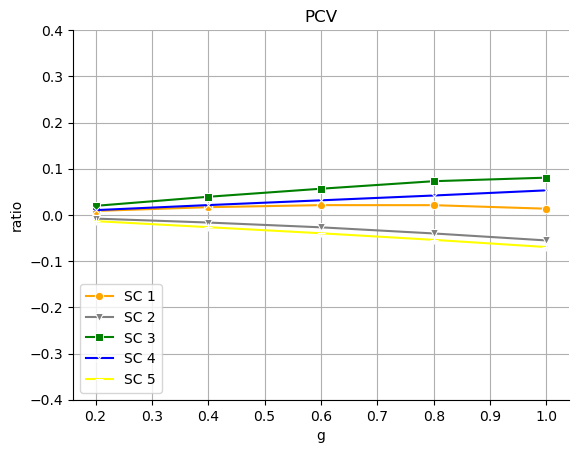

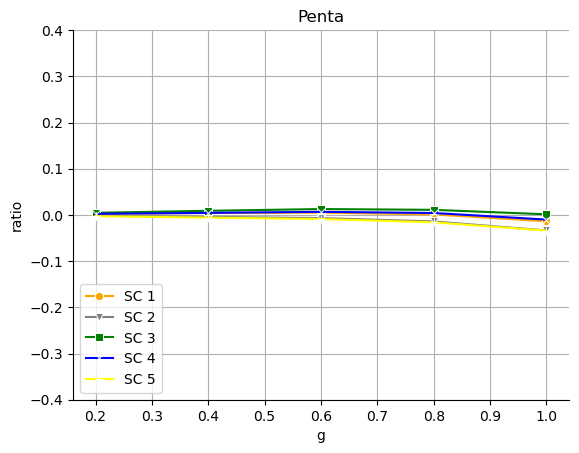

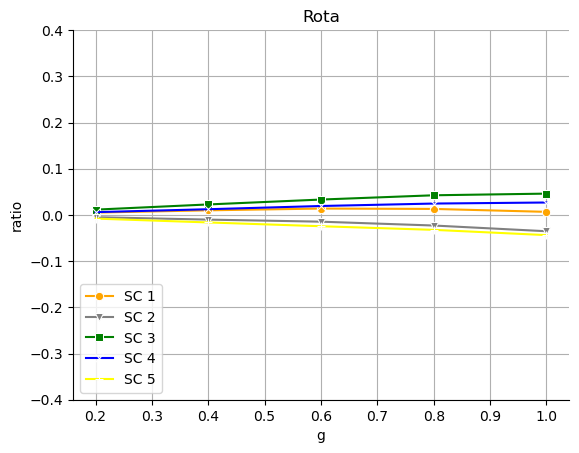

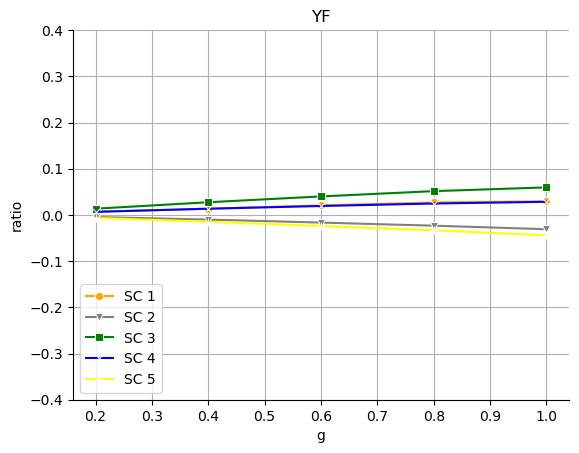

In [32]:
## fixign the y-axe levels for the benefit-mv plot

colorlist=['red','orange','gray','green','blue','yellow','purple']
mrklist=['p','o','v','s','x','+','d']
for vc in vaclist:
    dfref=df2[(df2['vac']==vc)&(df2['g']>0.00)]
    for ii in dfref.scenario.unique():
        sns.lineplot(x='g',y='ben_mv_mean', data=dfref[dfref['scenario']==ii],marker=mrklist[ii], color=colorlist[ii], label='SC '+str(ii))
        plt.title(str(vc))
        plt.xlabel('g')
        plt.ylabel('ratio')
        plt.ylim(-0.4, 0.4)
 
    # Add a legend
    plt.legend(loc='lower left')
 
    # Add a grid
    plt.grid(True)
 
    # Remove the top and right spines
    sns.despine()
 
    # Show the plot
    plt.show()

In [33]:
for i in dfref.scenario.unique():
    print(i)

1
2
3
4
5


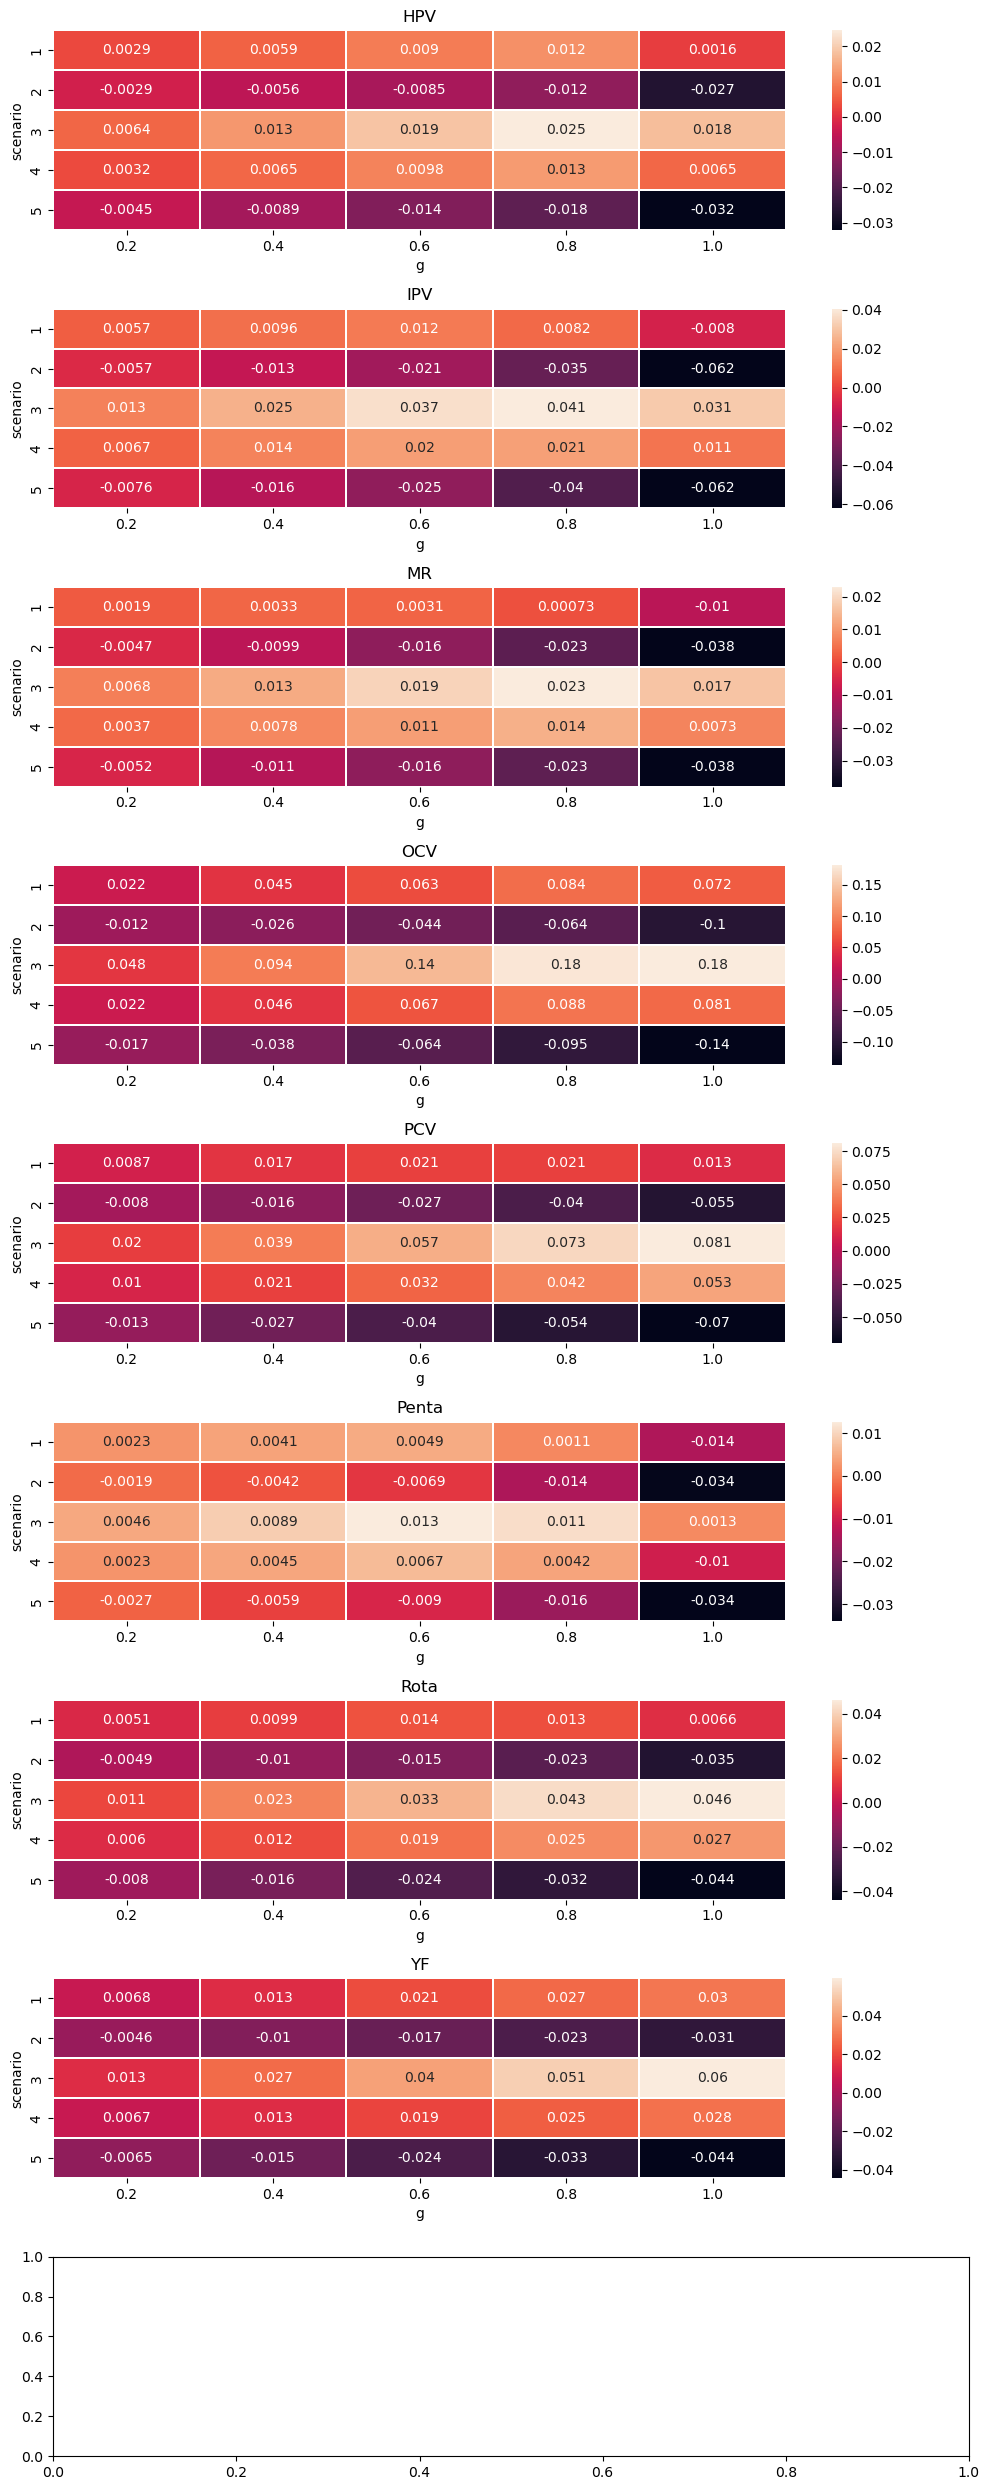

In [34]:
fig, axes = plt.subplots(9, 1, figsize=(10, 25))
 
i=0
for vc in vaclist:      
    dfint=df2[(df2['vac']==vc)&(df2['g']>0.00)].pivot(index="scenario", columns="g", values="ben_mv_mean")
    sns.heatmap(ax=axes[i], data=dfint,annot=True, linewidth=.1)#, vmin=-3.6e8, vmax=1.2e8)
    axes[i].set_title(vc)
    i=i+1
plt.tight_layout()

plt.show()


In [35]:
df2[df2['vac']=='YF'].pivot(index='scenario', columns='g', values='ben_mv_mean').min(axis='columns')

scenario
1    0.000
2   -0.031
3    0.000
4    0.000
5   -0.044
dtype: float64

### Table 6. Sum of minimum and maximum absolute values across vaccines and corresponding proportion of MV

In [36]:
pd.set_option('display.precision', 2)

In [37]:
dfabsben_hpv=abs(df2[df2['vac']=='HPV'].pivot(index='scenario', columns='g', values='benefit_mean')).describe().loc[["min","max"]]
dfabsben_ipv=abs(df2[df2['vac']=='IPV'].pivot(index='scenario', columns='g', values='benefit_mean')).describe().loc[["min","max"]]
#dfabsben_measles=abs(df2[df2['vac']=='Measles'].pivot(index='scenario', columns='g', values='benefit_mean')).describe().loc[["min","max"]]
dfabsben_ocv=abs(df2[df2['vac']=='OCV'].pivot(index='scenario', columns='g', values='benefit_mean')).describe().loc[["min","max"]]
dfabsben_mr=abs(df2[df2['vac']=='MR'].pivot(index='scenario', columns='g', values='benefit_mean')).describe().loc[["min","max"]]
dfabsben_pcv=abs(df2[df2['vac']=='PCV'].pivot(index='scenario', columns='g', values='benefit_mean')).describe().loc[["min","max"]]
dfabsben_penta=abs(df2[df2['vac']=='Penta'].pivot(index='scenario', columns='g', values='benefit_mean')).describe().loc[["min","max"]]
dfabsben_rota=abs(df2[df2['vac']=='Rota'].pivot(index='scenario', columns='g', values='benefit_mean')).describe().loc[["min","max"]]
#dfabsben_tt=abs(df2[df2['vac']=='TT'].pivot(index='scenario', columns='g', values='benefit_mean')).describe().loc[["min","max"]]
dfabsben_yf=abs(df2[df2['vac']=='YF'].pivot(index='scenario', columns='g', values='benefit_mean')).describe().loc[["min","max"]]

In [38]:
sum([dfabsben_hpv,dfabsben_ipv,dfabsben_ocv,dfabsben_mr,dfabsben_pcv,dfabsben_penta,dfabsben_rota,dfabsben_yf])

g,0.0,0.2,0.4,0.6,0.8,1.0
min,0.0,8.73e+06,1.76e+07,2.46e+07,2.80e+07,2.32e+07
max,0.0,2.19e+07,4.31e+07,6.31e+07,8.12e+07,9.22e+07


In [39]:
print(dfabsben_hpv)
print(dfabsben_ipv)
print(dfabsben_ocv)
print(dfabsben_mr)
print(dfabsben_pcv)
print(dfabsben_penta)
print(dfabsben_rota)
print(dfabsben_yf)

g    0.0        0.2       0.4       0.6       0.8       1.0
min  0.0  241318.61  4.69e+05  7.14e+05  9.52e+05  1.34e+05
max  0.0  517970.14  1.02e+06  1.52e+06  2.00e+06  2.70e+06
g    0.0        0.2       0.4       0.6       0.8       1.0
min  0.0  410044.47  6.82e+05  8.29e+05  4.83e+05  6.94e+05
max  0.0  933693.00  1.76e+06  2.56e+06  3.08e+06  4.89e+06
g    0.0       0.2       0.4       0.6       0.8       1.0
min  0.0  2.75e+06  5.85e+06  9.44e+06  1.35e+07  1.30e+07
max  0.0  8.14e+06  1.59e+07  2.37e+07  3.07e+07  3.15e+07
g    0.0        0.2       0.4       0.6       0.8       1.0
min  0.0  251862.27  4.45e+05  3.96e+05  5.12e+04  9.89e+05
max  0.0  920679.03  1.73e+06  2.57e+06  3.37e+06  5.49e+06
g    0.0       0.2       0.4       0.6       0.8       1.0
min  0.0  3.75e+06  7.54e+06  9.49e+06  9.35e+06  5.86e+06
max  0.0  8.35e+06  1.67e+07  2.40e+07  3.09e+07  3.42e+07
g    0.0        0.2        0.4        0.6        0.8       1.0
min  0.0  111611.09  229726.27  276495.10  